# Implémentation de LeNet-5 pour la reconnaissance des caractères manuscrits Tifinagh
Dataset : *Amazigh Handwritten Character Database* (AMHCD) – Kaggle amazigh-handwritten-character-database-amhcd
### Plan du notebook
1. Imports, reproductibilité, configuration
2. Chargement et exploration du dataset
3. Prétraitement et découpage Train / Validation / Test
4. Architecture LeNet-5 (paramétrable) et fonctions utilitaires
5. Expérience 1 : SGD – Expérience 2 : Adam
6. Comparaison SGD / Adam, courbes, matrices de confusion, rapports de classification
7. Visualisation des feature maps
8. Analyse automatique et sauvegarde des résultats
9. Expérience bonus (séparée du modèle de référence)



In [26]:
# Installation (Colab). kagglehub permet de télécharger le dataset public sans clé API dans la plupart des cas.
!pip install -q kagglehub

## 1. Importations

In [27]:
import os, re, json, random, zipfile, subprocess, hashlib, shutil, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
print("TensorFlow :", tf.__version__, "| Keras :", keras.__version__)
print("GPU disponibles :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0 | Keras : 3.13.2
GPU disponibles : []


## 2. Reproductibilité

In [28]:
SEED = 42
ENABLE_OP_DETERMINISM = False   # True = plus reproductible sur GPU, mais plus lent

def set_global_seed(seed=SEED):
    """Fixe toutes les graines (Python, NumPy, TensorFlow/Keras)."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    try:
        keras.utils.set_random_seed(seed)
    except AttributeError:
        pass

set_global_seed()
if ENABLE_OP_DETERMINISM:
    tf.config.experimental.enable_op_determinism()
print(f"Graine globale : {SEED}")

Graine globale : 42


## 3. Configuration

In [29]:
# ----- Dataset -----
DATASET_SLUG = "benaddym/amazigh-handwritten-character-database-amhcd"
DATA_DIR = None   # Optionnel : chemin local déjà téléchargé, ex. "/content/amhcd". None = téléchargement automatique.
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".gif"}
LABEL_DISPLAY = {}  # Optionnel : {"nom_dossier": "ⴰ"} pour afficher de vrais caractères Tifinagh dans les figures

# ----- Données -----
IMG_SIZE = 32
NUM_CHANNELS = 1
NUM_CLASSES = 33
TEST_SIZE = 0.15
VAL_SIZE = 0.15          # fraction du dataset total (pas du train)

# ----- Entraînement -----
BATCH_SIZE = 64
EPOCHS = 50
LEARNING_RATE_SGD = 0.01
LEARNING_RATE_ADAM = 0.001
SGD_MOMENTUM = 0.9
EARLY_STOPPING_PATIENCE = 10   # None pour désactiver l'arrêt anticipé

# ----- Architecture LeNet-5 -----
CONV1_FILTERS = 6
CONV1_KERNEL = 5
POOL_SIZE = 2
POOL_STRIDE = 2
CONV2_FILTERS = 16
CONV2_KERNEL = 5
FC1_UNITS = 120
FC2_UNITS = 84
ACTIVATION = "relu"   # LeNet-5 original : tanh. ReLU est le choix moderne (gradients plus stables, convergence plus rapide).

# ----- Dossiers de sortie -----
RESULTS_DIR = Path("results")
FIG_DIR = RESULTS_DIR / "figures"
MODEL_DIR = RESULTS_DIR / "models"
METRICS_DIR = RESULTS_DIR / "metrics"
for d in (FIG_DIR, MODEL_DIR, METRICS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ----- Vérifications de cohérence -----
assert IMG_SIZE == 32, "Le sujet impose des images 32×32"
assert NUM_CHANNELS == 1, "Le sujet impose des images en niveaux de gris (1 canal)"
assert NUM_CLASSES == 33, "Le sujet impose 33 classes Tifinagh"

def save_fig(fig, name):
    """Sauvegarde une figure dans results/figures puis l'affiche."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[figure sauvegardée] {path}")

print("Configuration chargée.")

Configuration chargée.


## 4. Chargement du dataset
Téléchargement avec `kagglehub`, puis repli sur l'API Kaggle (`kaggle.json`) si nécessaire.
Vous pouvez aussi renseigner `DATA_DIR` à la main (dataset déjà présent sur Drive ou en local).

In [30]:
def extract_nested_zips(root):
    """Décompresse les archives .zip éventuellement présentes dans le dataset."""
    for z in list(Path(root).rglob("*.zip")):
        target = z.with_suffix("")
        if not target.exists():
            print(f"Décompression de {z.name} ...")
            with zipfile.ZipFile(z) as zf:
                zf.extractall(target)

def download_dataset():
    """Retourne le dossier racine du dataset (téléchargé ou fourni)."""
    if DATA_DIR:
        root = Path(DATA_DIR)
        assert root.exists(), f"DATA_DIR='{DATA_DIR}' n'existe pas."
        return root
    # 1) kagglehub
    try:
        import kagglehub
        root = Path(kagglehub.dataset_download(DATASET_SLUG))
        print("Téléchargé via kagglehub :", root)
        return root
    except Exception as e:
        print("kagglehub a échoué :", repr(e))
    # 2) API Kaggle
    kaggle_json = Path.home() / ".kaggle" / "kaggle.json"
    has_env = "KAGGLE_USERNAME" in os.environ and "KAGGLE_KEY" in os.environ
    if not kaggle_json.exists() and not has_env:
        try:
            from google.colab import files
            print("Veuillez uploader votre fichier kaggle.json (Kaggle > Settings > API > Create New Token).")
            uploaded = files.upload()
            assert "kaggle.json" in uploaded, "kaggle.json non fourni."
            kaggle_json.parent.mkdir(exist_ok=True)
            kaggle_json.write_bytes(uploaded["kaggle.json"])
        except ImportError:
            raise RuntimeError("Téléchargement impossible : configurez kaggle.json / KAGGLE_USERNAME+KAGGLE_KEY, "
                               "ou renseignez DATA_DIR avec un chemin local.")
    if kaggle_json.exists():
        kaggle_json.chmod(0o600)
    out = Path("data/amhcd")
    out.mkdir(parents=True, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", DATASET_SLUG, "-p", str(out), "--unzip"], check=True)
    return out

DATASET_ROOT = download_dataset()
extract_nested_zips(DATASET_ROOT)
print("Racine du dataset :", DATASET_ROOT)

Using Colab cache for faster access to the 'amazigh-handwritten-character-database-amhcd' dataset.
Téléchargé via kagglehub : /kaggle/input/amazigh-handwritten-character-database-amhcd
Racine du dataset : /kaggle/input/amazigh-handwritten-character-database-amhcd


### 4.1 Exploration automatique de la structure

In [31]:
def list_image_files(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)

def describe_structure(root, max_depth=3, max_lines=60):
    """Affiche l'arborescence (profondeur limitée) avec le nombre d'images par dossier."""
    root = Path(root)
    lines = []
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames.sort()
        depth = len(Path(dirpath).relative_to(root).parts)
        if depth > max_depth:
            dirnames[:] = []
            continue
        n_img = sum(Path(f).suffix.lower() in IMAGE_EXTENSIONS for f in filenames)
        lines.append(f"{'   ' * depth}{Path(dirpath).name or root.name}/  "
                     f"[{n_img} images directes, {len(dirnames)} sous-dossiers]")
    print("\n".join(lines[:max_lines]))
    if len(lines) > max_lines:
        print(f"... ({len(lines) - max_lines} lignes supplémentaires non affichées)")

all_files = [p for p in Path(DATASET_ROOT).rglob("*") if p.is_file()]
print("Extensions de fichiers trouvées :", dict(Counter(p.suffix.lower() for p in all_files)))
image_paths = list_image_files(DATASET_ROOT)
print(f"Nombre total d'images détectées : {len(image_paths)}")
assert len(image_paths) > 0, "Aucune image trouvée : vérifiez DATASET_ROOT / DATA_DIR."

print("\nArborescence :")
describe_structure(DATASET_ROOT)

# Caractéristiques brutes (taille / mode couleur) sur un échantillon
rng = np.random.default_rng(SEED)
sample_paths = rng.choice(np.array(image_paths, dtype=object), size=min(300, len(image_paths)), replace=False)
raw_info = Counter()
for p in sample_paths:
    with Image.open(p) as im:
        raw_info[(im.size, im.mode)] += 1
print("\nTailles / modes (échantillon de 300 images) :")
for (size, mode), n in raw_info.most_common():
    print(f"  taille={size}, mode={mode} : {n} images")

Extensions de fichiers trouvées : {'.jpeg': 51480, '.txt': 2}
Nombre total d'images détectées : 51480

Arborescence :
amazigh-handwritten-character-database-amhcd/  [0 images directes, 3 sous-dossiers]
   AMHCD_64/  [0 images directes, 1 sous-dossiers]
      AMHCD_64/  [0 images directes, 33 sous-dossiers]
         ya/  [780 images directes, 0 sous-dossiers]
         yab/  [780 images directes, 0 sous-dossiers]
         yach/  [780 images directes, 0 sous-dossiers]
         yad/  [780 images directes, 0 sous-dossiers]
         yadd/  [780 images directes, 0 sous-dossiers]
         yae/  [780 images directes, 0 sous-dossiers]
         yaf/  [780 images directes, 0 sous-dossiers]
         yag/  [780 images directes, 0 sous-dossiers]
         yagh/  [780 images directes, 0 sous-dossiers]
         yagw/  [780 images directes, 0 sous-dossiers]
         yah/  [780 images directes, 0 sous-dossiers]
         yahh/  [780 images directes, 0 sous-dossiers]
         yaj/  [780 images directes, 0 s

### 4.2 Détection des classes

In [25]:
def natural_key(s):
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", str(s))]

def infer_labels(paths, root, expected_classes=NUM_CLASSES):
    """Déduit le label depuis l'arborescence : on teste le dossier parent, puis le grand-parent, etc.
    On retient le premier niveau qui donne exactement `expected_classes` classes distinctes."""
    root = Path(root)

    def label_at(p, level):
        parts = p.relative_to(root).parts[:-1]
        return parts[-level] if len(parts) >= level else None

    candidates = {}
    for level in (1, 2, 3):
        labels = [label_at(p, level) for p in paths]
        if None not in labels:
            candidates[level] = labels
            print(f"  niveau {level} (dossier à {level} cran(s) au-dessus du fichier) : {len(set(labels))} valeurs distinctes")
    assert candidates, ("Les images ne sont pas rangées dans des sous-dossiers par classe. "
                        "Adaptez infer_labels() (labels dans un CSV ou dans le nom des fichiers).")
    chosen = next((lvl for lvl, lab in candidates.items() if len(set(lab)) == expected_classes), None)
    if chosen is None:
        chosen = min(candidates)
        print(f" Aucun niveau ne donne exactement {expected_classes} classes. Niveau {chosen} utilisé par défaut.")
    else:
        print(f" Niveau {chosen} retenu ({expected_classes} classes).")
    return pd.DataFrame({"path": [str(p) for p in paths], "label": candidates[chosen]})

df = infer_labels(image_paths, DATASET_ROOT)
n_found = df["label"].nunique()
print(f"\nNombre de classes détectées : {n_found}")
assert n_found == NUM_CLASSES, (
    f" ALERTE : {n_found} classes détectées au lieu de {NUM_CLASSES}. "
    f"Classes trouvées : {sorted(df['label'].unique(), key=natural_key)}. "
    "Vérifiez la structure du dataset avant de continuer.")

class_names = sorted(df["label"].unique(), key=natural_key)
class_to_idx = {c: i for i, c in enumerate(class_names)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
df["y"] = df["label"].map(class_to_idx)
display_names = [LABEL_DISPLAY.get(c, str(c)) for c in class_names]
print("Classes :", class_names)

# Police Tifinagh (optionnel) si les noms de classes sont de vrais caractères Unicode Tifinagh
def setup_tifinagh_font():
    from matplotlib import font_manager as fm
    cands = [f for f in fm.findSystemFonts() if "tifinagh" in f.lower()]
    if cands:
        fm.fontManager.addfont(cands[0])
        plt.rcParams["font.family"] = [fm.FontProperties(fname=cands[0]).get_name(), "DejaVu Sans"]
        print("Police Tifinagh activée :", Path(cands[0]).name)
    else:
        print("Aucune police Tifinagh trouvée. Pour l'installer : !apt-get -qq install fonts-noto-core puis relancer cette cellule.")

if any("\u2d30" <= ch <= "\u2d7f" for name in display_names for ch in name):
    setup_tifinagh_font()

  niveau 1 (dossier à 1 cran(s) au-dessus du fichier) : 33 valeurs distinctes
  niveau 2 (dossier à 2 cran(s) au-dessus du fichier) : 1 valeurs distinctes
  niveau 3 (dossier à 3 cran(s) au-dessus du fichier) : 2 valeurs distinctes
 Niveau 1 retenu (33 classes).

Nombre de classes détectées : 33
Classes : ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']


## 5. Exploration du dataset

Nombre total d'images : 51480
Nombre de classes     : 33
Images par classe     : min=1560, max=1560, moyenne=1560.0, ratio max/min=1.00


label,ya,yab,yach,yad,yadd,yae,yaf,yag,yagh,yagw,...,yat,yatt,yaw,yax,yay,yaz,yazz,yey,yi,yu
nb_images,1560,1560,1560,1560,1560,1560,1560,1560,1560,1560,...,1560,1560,1560,1560,1560,1560,1560,1560,1560,1560


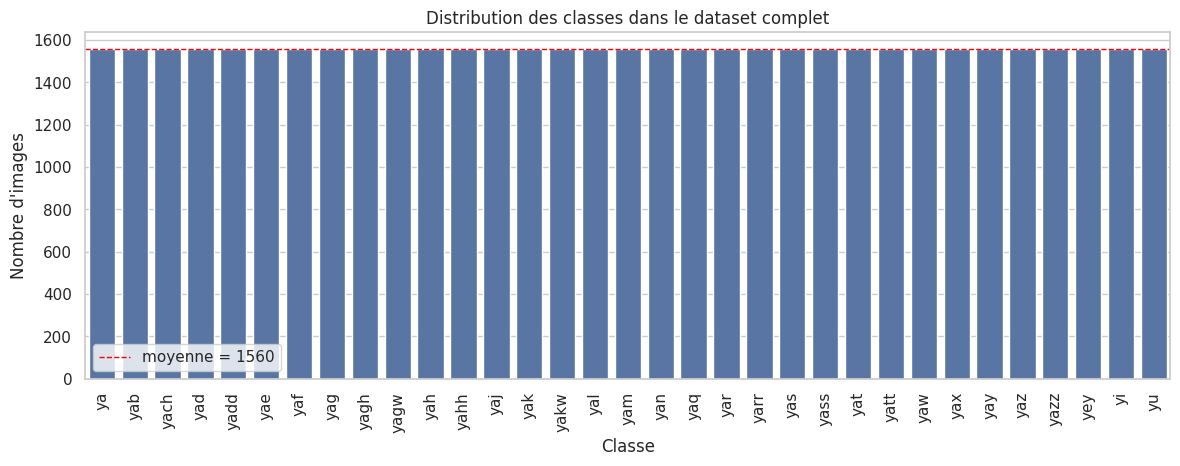

[figure sauvegardée] results/figures/class_distribution_full.png


In [32]:
counts = df["label"].value_counts().reindex(class_names)
print(f"Nombre total d'images : {len(df)}")
print(f"Nombre de classes     : {len(class_names)}")
print(f"Images par classe     : min={counts.min()}, max={counts.max()}, moyenne={counts.mean():.1f}, "
      f"ratio max/min={counts.max() / counts.min():.2f}")
display(counts.rename("nb_images").to_frame().T)

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.barplot(x=display_names, y=counts.values, color="#4C72B0", ax=ax)
ax.set_title("Distribution des classes dans le dataset complet")
ax.set_xlabel("Classe"); ax.set_ylabel("Nombre d'images")
ax.tick_params(axis="x", rotation=90)
ax.axhline(counts.mean(), color="red", ls="--", lw=1, label=f"moyenne = {counts.mean():.0f}")
ax.legend()
save_fig(fig, "class_distribution_full.png")

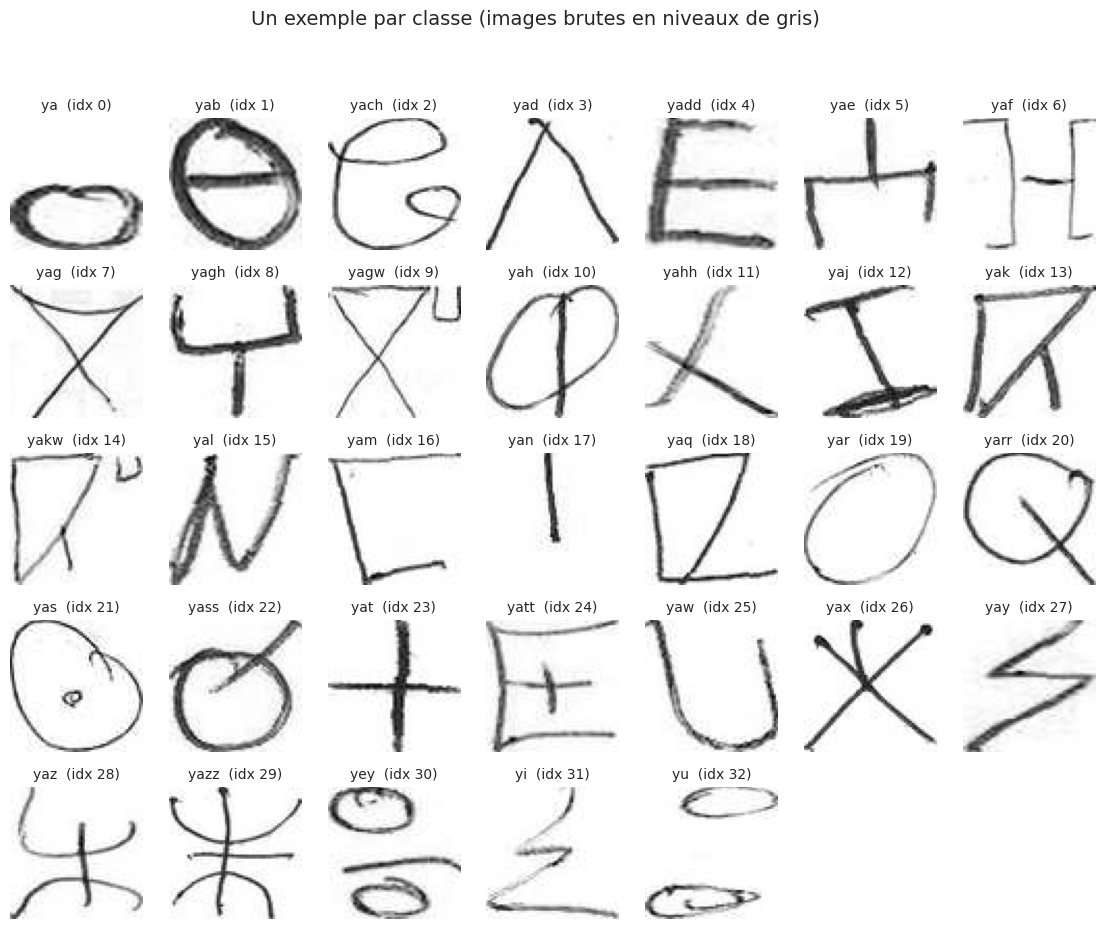

[figure sauvegardée] results/figures/examples_one_per_class.png


In [33]:
def load_image(path):
    """Lit une image directement en niveaux de gris (gère les images RGB)."""
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        try:
            img = np.array(Image.open(path).convert("L"))
        except Exception:
            return None
    return img

# Un exemple aléatoire par classe (images brutes converties en gris)
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(5, 7, figsize=(14, 10.5))
for ax in axes.ravel():
    ax.axis("off")
for i, cls in enumerate(class_names):
    row = df[df["label"] == cls].sample(1, random_state=int(rng.integers(0, 10_000))).iloc[0]
    img = load_image(row["path"])
    ax = axes.ravel()[i]
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{display_names[i]}  (idx {i})", fontsize=10)
fig.suptitle("Un exemple par classe (images brutes en niveaux de gris)", fontsize=14)
save_fig(fig, "examples_one_per_class.png")

## 6. Prétraitement
- conversion en niveaux de gris ;
- redimensionnement en 32×32 (interpolation INTER_AREA, adaptée à la réduction) ;
- normalisation des pixels dans [0, 1] ;
- encodage des labels en entiers (perte sparse_categorical_crossentropy).

Aucune data augmentation dans le modèle de référence.

In [34]:
def preprocess_image(img, img_size=IMG_SIZE):
    """uint8 (H, W) -> float32 (img_size, img_size, 1) normalisé dans [0, 1]."""
    img = cv2.resize(img, (img_size, img_size), interpolation=cv2.INTER_AREA)
    return (img.astype("float32") / 255.0)[..., np.newaxis]

def load_images(paths):
    """Charge une liste de chemins -> liste d'images grises brutes (None si illisible)."""
    return [load_image(p) for p in tqdm(paths, desc="Lecture des images")]

def preprocess_dataset(dataframe):
    """Retourne X (N, 32, 32, 1), y (N,) et le DataFrame des images valides."""
    raw = load_images(dataframe["path"].tolist())
    valid = np.array([r is not None for r in raw])
    if not valid.all():
        print(f" {(~valid).sum()} image(s) illisible(s) ignorée(s).")
    X = np.stack([preprocess_image(r) for r in raw if r is not None]).astype("float32")
    kept = dataframe[valid].reset_index(drop=True)
    return X, kept["y"].to_numpy().astype("int64"), kept

X, y, df_valid = preprocess_dataset(df)

assert X.shape[1:] == (IMG_SIZE, IMG_SIZE, NUM_CHANNELS), f"Forme inattendue : {X.shape}"
assert 0.0 <= X.min() and X.max() <= 1.0, "Normalisation incorrecte"
assert len(np.unique(y)) == NUM_CLASSES
print(f"X : {X.shape}, dtype={X.dtype}, min={X.min():.2f}, max={X.max():.2f}")
print(f"y : {y.shape}, {len(np.unique(y))} classes")

Lecture des images:   0%|          | 0/51480 [00:00<?, ?it/s]

X : (51480, 32, 32, 1), dtype=float32, min=0.15, max=1.00
y : (51480,), 33 classes


## 7. Séparation Train / Validation / Test (stratifiée)

,Ensemble,Taille,Part (%)
0,Train,36035,70.0
1,Validation,7723,15.0
2,Test,7722,15.0


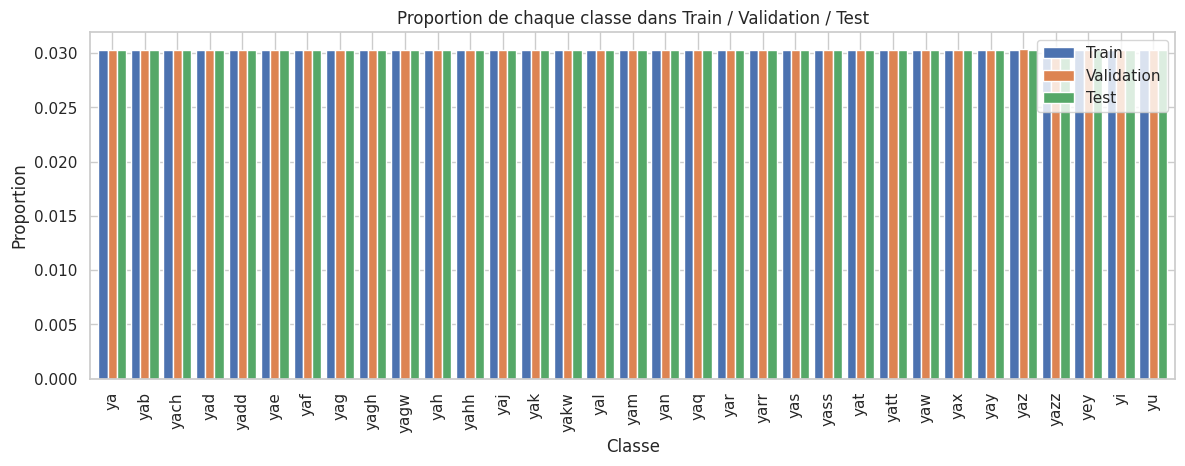

[figure sauvegardée] results/figures/class_distribution_splits.png
Doublons exacts train∩val  : 5440
Doublons exacts train∩test : 5465
Doublons exacts val∩test   : 1105


In [35]:
indices = np.arange(len(y))
idx_trainval, idx_test = train_test_split(indices, test_size=TEST_SIZE, stratify=y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                      stratify=y[idx_trainval], random_state=SEED)

X_train, y_train = X[idx_train], y[idx_train]
X_val, y_val = X[idx_val], y[idx_val]
X_test, y_test = X[idx_test], y[idx_test]

# Aucun indice partagé entre les ensembles
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
assert len(idx_train) + len(idx_val) + len(idx_test) == len(y)

split_table = pd.DataFrame({
    "Ensemble": ["Train", "Validation", "Test"],
    "Taille": [len(y_train), len(y_val), len(y_test)],
    "Part (%)": [100 * len(y_train) / len(y), 100 * len(y_val) / len(y), 100 * len(y_test) / len(y)],
}).round(2)
display(split_table)

# Distribution des classes (en proportion) dans chaque ensemble
prop = pd.DataFrame({
    "Train": np.bincount(y_train, minlength=NUM_CLASSES) / len(y_train),
    "Validation": np.bincount(y_val, minlength=NUM_CLASSES) / len(y_val),
    "Test": np.bincount(y_test, minlength=NUM_CLASSES) / len(y_test),
}, index=display_names)
fig, ax = plt.subplots(figsize=(14, 4.5))
prop.plot(kind="bar", ax=ax, width=0.85)
ax.set_title("Proportion de chaque classe dans Train / Validation / Test")
ax.set_xlabel("Classe"); ax.set_ylabel("Proportion")
save_fig(fig, "class_distribution_splits.png")

# Contrôle de fuite : doublons exacts d'images entre ensembles (rapportés, non supprimés)
def hashes(arr):
    return {hashlib.md5(a.tobytes()).hexdigest() for a in arr}
h_train, h_val, h_test = hashes(X_train), hashes(X_val), hashes(X_test)
print("Doublons exacts train∩val  :", len(h_train & h_val))
print("Doublons exacts train∩test :", len(h_train & h_test))
print("Doublons exacts val∩test   :", len(h_val & h_test))

## 8. Architecture LeNet-5 (modèle de référence)

32×32×1 → C1 (6×28×28) → S2 (6×14×14) → C3 (16×10×10) → S4 (16×5×5) → Flatten (400) → C5 (120) → F6 (84) → Sortie (33)

Keras utilise le format *channels-last* : « 6×28×28 » du sujet correspond à la forme (28, 28, 6).
Pas de Dropout ni de Batch Normalization dans le modèle de référence.

In [36]:
def build_lenet5(img_size=IMG_SIZE, channels=NUM_CHANNELS, num_classes=NUM_CLASSES,
                 conv1_filters=CONV1_FILTERS, conv1_kernel=CONV1_KERNEL,
                 pool_size=POOL_SIZE, pool_stride=POOL_STRIDE,
                 conv2_filters=CONV2_FILTERS, conv2_kernel=CONV2_KERNEL,
                 fc1_units=FC1_UNITS, fc2_units=FC2_UNITS,
                 activation=ACTIVATION, name="LeNet5"):
    """LeNet-5 modifié, entièrement paramétrable (API fonctionnelle Keras).
    - Convolutions en padding 'valid' : 32 -> 28 -> (pool) 14 -> 10 -> (pool) 5.
    - AveragePooling (et non MaxPooling) conformément au sujet.
    - C5 est implémentée comme une couche Dense sur le vecteur aplati (400 -> 120), équivalent à une convolution 5×5 sur 16@5×5.
    - `activation` : tanh dans l'article original ; ReLU par défaut ici (pratique moderne).
    - Sortie softmax : distribution de probabilité sur les classes."""
    inputs = keras.Input(shape=(img_size, img_size, channels), name="Input")
    x = layers.Conv2D(conv1_filters, conv1_kernel, padding="valid", activation=activation, name="C1")(inputs)
    x = layers.AveragePooling2D(pool_size=pool_size, strides=pool_stride, name="S2")(x)
    x = layers.Conv2D(conv2_filters, conv2_kernel, padding="valid", activation=activation, name="C3")(x)
    x = layers.AveragePooling2D(pool_size=pool_size, strides=pool_stride, name="S4")(x)
    x = layers.Flatten(name="Flatten")(x)
    x = layers.Dense(fc1_units, activation=activation, name="C5")(x)
    x = layers.Dense(fc2_units, activation=activation, name="F6")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="Output")(x)
    return keras.Model(inputs, outputs, name=name)

def verify_architecture(model):
    """Vérifie les dimensions exigées par le sujet (valable pour la configuration par défaut)."""
    expected = {"Input": (None, 32, 32, 1), "C1": (None, 28, 28, 6), "S2": (None, 14, 14, 6),
                "C3": (None, 10, 10, 16), "S4": (None, 5, 5, 16), "Flatten": (None, 400),
                "C5": (None, 120), "F6": (None, 84), "Output": (None, 33)}
    rows = []
    for lname, shape in expected.items():
        actual = tuple(model.get_layer(lname).output.shape) if lname != "Input" else tuple(model.input.shape)
        rows.append({"Couche": lname, "Attendu": shape, "Obtenu": actual, "OK": actual == shape})
    report = pd.DataFrame(rows)
    display(report)
    assert report["OK"].all(), "❌ Les dimensions du modèle ne correspondent pas au sujet."
    assert isinstance(model.get_layer("S2"), layers.AveragePooling2D) and isinstance(model.get_layer("S4"), layers.AveragePooling2D)
    print(" Architecture conforme au sujet (32×32×1 → 28×28×6 → 14×14×6 → 10×10×16 → 5×5×16 → 120 → 84 → 33).")

model_ref = build_lenet5()
model_ref.summary()
verify_architecture(model_ref)
# 156 + 2 416 + 48 120 + 10 164 + 2 805 = 63 661 paramètres entraînables
assert model_ref.count_params() == 63661, f"Nombre de paramètres inattendu : {model_ref.count_params()}"
print(f"Nombre total de paramètres : {model_ref.count_params():,}")

Model: "LeNet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input (InputLayer)              │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1 (Conv2D)                     │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2 (AveragePooling2D)           │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3 (Conv2D)                     │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4 (AveragePooling2D)           │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5 (Dense)                      │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6 (Dense)                      │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 33)             │         2,805 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,661 (248.68 KB)

 Trainable params: 63,661 (248.68 KB)

 Non-trainable params: 0 (0.00 B)

,Couche,Attendu,Obtenu,OK
0,Input,"(None, 32, 32, 1)","(None, 32, 32, 1)",True
1,C1,"(None, 28, 28, 6)","(None, 28, 28, 6)",True
2,S2,"(None, 14, 14, 6)","(None, 14, 14, 6)",True
3,C3,"(None, 10, 10, 16)","(None, 10, 10, 16)",True
4,S4,"(None, 5, 5, 16)","(None, 5, 5, 16)",True
5,Flatten,"(None, 400)","(None, 400)",True
6,C5,"(None, 120)","(None, 120)",True
7,F6,"(None, 84)","(None, 84)",True
8,Output,"(None, 33)","(None, 33)",True


 Architecture conforme au sujet (32×32×1 → 28×28×6 → 14×14×6 → 10×10×16 → 5×5×16 → 120 → 84 → 33).
Nombre total de paramètres : 63,661


## 9. Fonctions réutilisables (compilation, entraînement, évaluation, visualisation)

In [37]:
def compile_model(model, optimizer_name, learning_rate, momentum=SGD_MOMENTUM):
    """Compile le modèle avec SGD ou Adam. Perte : entropie croisée sur labels entiers."""
    name = optimizer_name.lower()
    if name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate=learning_rate, momentum=momentum)
    elif name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    else:
        raise ValueError(f"Optimiseur inconnu : {optimizer_name}")
    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

def train_model(model, X_train, y_train, X_val, y_val, run_name, epochs=EPOCHS, batch_size=BATCH_SIZE,
                train_dataset=None, extra_callbacks=None):
    """Entraîne le modèle ; sauvegarde le meilleur modèle (val_accuracy) dans results/models.
    Retourne (history_df, chemin_du_meilleur_modèle)."""
    ckpt_path = MODEL_DIR / f"{run_name}_best.keras"
    callbacks = [keras.callbacks.ModelCheckpoint(str(ckpt_path), monitor="val_accuracy", mode="max",
                                                 save_best_only=True, verbose=0)]
    if EARLY_STOPPING_PATIENCE:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                                       patience=EARLY_STOPPING_PATIENCE,
                                                       restore_best_weights=True, verbose=1))
    callbacks += (extra_callbacks or [])
    if train_dataset is not None:
        hist = model.fit(train_dataset, validation_data=(X_val, y_val), epochs=epochs, callbacks=callbacks, verbose=2)
    else:
        hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                         batch_size=batch_size, shuffle=True, callbacks=callbacks, verbose=2)
    history_df = pd.DataFrame(hist.history)
    history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
    history_df.to_csv(METRICS_DIR / f"{run_name}_history.csv", index=False)
    return history_df, ckpt_path

def evaluate_model(model, X, y, class_names_display):
    """Évalue le modèle : loss, accuracy, prédictions, rapport de classification (DataFrame), matrice de confusion."""
    loss, acc = model.evaluate(X, y, batch_size=256, verbose=0)
    y_pred = model.predict(X, batch_size=256, verbose=0).argmax(axis=1)
    labels = list(range(len(class_names_display)))
    rep = classification_report(y, y_pred, labels=labels, target_names=[str(n) for n in class_names_display],
                                output_dict=True, zero_division=0)
    overall_acc = rep.pop("accuracy")
    report_df = pd.DataFrame(rep).T
    report_df.loc["accuracy"] = [np.nan, np.nan, overall_acc, len(y)]
    report_df = report_df.loc[[str(n) for n in class_names_display] + ["accuracy", "macro avg", "weighted avg"]]
    cm = confusion_matrix(y, y_pred, labels=labels)
    return {"loss": float(loss), "accuracy": float(acc), "y_pred": y_pred, "report_df": report_df, "cm": cm}

def plot_training_history(history_df, title, filename):
    """Courbes accuracy et loss (train vs validation) avec le meilleur epoch repéré."""
    best_epoch = int(history_df["val_accuracy"].idxmax()) + 1
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metric, label in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        ax.plot(history_df["epoch"], history_df[metric], label="Train", lw=2)
        ax.plot(history_df["epoch"], history_df[f"val_{metric}"], label="Validation", lw=2)
        ax.axvline(best_epoch, color="gray", ls=":", label=f"meilleur epoch ({best_epoch})")
        ax.set_title(f"{label} – {title}"); ax.set_xlabel("Epoch"); ax.set_ylabel(label)
        ax.grid(True, alpha=0.4); ax.legend()
    save_fig(fig, filename)

def plot_confusion_matrix(cm, class_labels, title, filename, normalize=False):
    """Matrice de confusion Seaborn avec les noms de classes. normalize=True : proportions par ligne (rappel)."""
    if normalize:
        data = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        annot = np.where(data > 0, np.char.mod("%.2f", data), "")
    else:
        data = cm
        annot = np.where(cm > 0, cm.astype(str), "")
    fig, ax = plt.subplots(figsize=(17, 14))
    sns.heatmap(data, annot=annot, fmt="", cmap="Blues", xticklabels=class_labels, yticklabels=class_labels,
                annot_kws={"size": 6}, linewidths=0.2, linecolor="#eeeeee", cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle")
    ax.tick_params(axis="x", rotation=90)
    save_fig(fig, filename)

def visualize_feature_maps(model, X, y, class_labels, index=None, class_index=None, filename_prefix="feature_maps"):
    """Affiche l'image choisie, les 6 cartes de C1 et les 16 cartes de C3 (modèle intermédiaire Keras).
    Sélection : `index` (indice dans X) ou `class_index` (première image de cette classe) ; défaut : 0."""
    if index is None:
        index = int(np.where(y == class_index)[0][0]) if class_index is not None else 0
    img = X[index]
    extractor = keras.Model(inputs=model.inputs, outputs=[model.get_layer("C1").output, model.get_layer("C3").output])
    c1, c3 = [o[0] for o in extractor.predict(img[None, ...], verbose=0)]
    pred = int(model.predict(img[None, ...], verbose=0).argmax())
    head = f"image test #{index} – vraie classe : {class_labels[y[index]]} | prédite : {class_labels[pred]}"

    # Image + C1
    n1 = c1.shape[-1]
    fig, axes = plt.subplots(1, n1 + 1, figsize=(2.2 * (n1 + 1), 3))
    axes[0].imshow(img[..., 0], cmap="gray"); axes[0].set_title("Image originale\n(32×32)"); axes[0].axis("off")
    for k in range(n1):
        axes[k + 1].imshow(c1[..., k], cmap="viridis")
        axes[k + 1].set_title(f"C1 – filtre {k + 1}\n{c1.shape[0]}×{c1.shape[1]}", fontsize=9)
        axes[k + 1].axis("off")
    fig.suptitle(f"Feature maps de C1 – {head}", y=1.08)
    save_fig(fig, f"{filename_prefix}_C1.png")

    # C3
    n3 = c3.shape[-1]
    cols = 4
    rows = int(np.ceil(n3 / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(2.4 * cols, 2.5 * rows))
    for ax in axes.ravel():
        ax.axis("off")
    for k in range(n3):
        ax = axes.ravel()[k]
        ax.imshow(c3[..., k], cmap="viridis")
        ax.set_title(f"C3 – filtre {k + 1}  ({c3.shape[0]}×{c3.shape[1]})", fontsize=9)
    fig.suptitle(f"Feature maps de C3 – {head}", y=1.0)
    plt.tight_layout()
    save_fig(fig, f"{filename_prefix}_C3.png")

print("Fonctions définies.")

Fonctions définies.


## 10. Pipeline d'une expérience complète

In [38]:
RESULTS = {}

def run_experiment(run_name, optimizer_name, learning_rate, builder=build_lenet5, builder_kwargs=None,
                   train_dataset=None, extra_callbacks=None):
    """Construit, compile, entraîne et évalue un modèle ; sauvegarde tout dans results/."""
    print("=" * 80)
    print(f"EXPÉRIENCE : {run_name} | optimiseur = {optimizer_name} | learning rate = {learning_rate}")
    print("=" * 80)
    set_global_seed(SEED)          # même initialisation pour toutes les expériences
    model = builder(**(builder_kwargs or {}))
    compile_model(model, optimizer_name, learning_rate)
    history_df, ckpt_path = train_model(model, X_train, y_train, X_val, y_val, run_name,
                                        train_dataset=train_dataset, extra_callbacks=extra_callbacks)
    best_model = keras.models.load_model(ckpt_path)     # meilleur modèle selon val_accuracy

    train_loss, train_acc = best_model.evaluate(X_train, y_train, batch_size=256, verbose=0)
    val_loss, val_acc = best_model.evaluate(X_val, y_val, batch_size=256, verbose=0)
    test_eval = evaluate_model(best_model, X_test, y_test, display_names)

    best_epoch = int(history_df["val_accuracy"].idxmax()) + 1
    plot_training_history(history_df, run_name, f"{run_name}_training_curves.png")

    print(f"\n--- Résultats {run_name} (meilleur modèle, epoch {best_epoch}) ---")
    print(f"Train      : loss={train_loss:.4f} | accuracy={train_acc:.4f}")
    print(f"Validation : loss={val_loss:.4f} | accuracy={val_acc:.4f}")
    print(f"Test       : loss={test_eval['loss']:.4f} | accuracy={test_eval['accuracy']:.4f}")
    print("\nHistorique – dernières epochs :")
    display(history_df.tail(5).round(4))
    print("\nClassification report (test) :")
    display(test_eval["report_df"].round(3))

    plot_confusion_matrix(test_eval["cm"], display_names, f"Matrice de confusion – {run_name} (test)",
                          f"{run_name}_confusion_matrix.png")
    plot_confusion_matrix(test_eval["cm"], display_names, f"Matrice de confusion normalisée – {run_name} (test)",
                          f"{run_name}_confusion_matrix_normalized.png", normalize=True)

    test_eval["report_df"].to_csv(METRICS_DIR / f"{run_name}_classification_report.csv")
    pd.DataFrame(test_eval["cm"], index=display_names, columns=display_names).to_csv(METRICS_DIR / f"{run_name}_confusion_matrix.csv")
    summary = {"run": run_name, "optimizer": optimizer_name, "learning_rate": learning_rate, "best_epoch": best_epoch,
               "epochs_run": int(len(history_df)), "params": int(best_model.count_params()),
               "train_loss": float(train_loss), "train_accuracy": float(train_acc),
               "val_loss": float(val_loss), "val_accuracy": float(val_acc),
               "test_loss": test_eval["loss"], "test_accuracy": test_eval["accuracy"]}
    (METRICS_DIR / f"{run_name}_metrics.json").write_text(json.dumps(summary, indent=2))

    RESULTS[run_name] = {"summary": summary, "history": history_df, "model": best_model,
                         "report_df": test_eval["report_df"], "cm": test_eval["cm"], "y_pred": test_eval["y_pred"]}
    return RESULTS[run_name]

## 11. Expérience 1 – SGD

EXPÉRIENCE : LeNet5_SGD | optimiseur = sgd | learning rate = 0.01
Epoch 1/50
564/564 - 20s - 36ms/step - accuracy: 0.2326 - loss: 2.7753 - val_accuracy: 0.7554 - val_loss: 0.8972
Epoch 2/50
564/564 - 22s - 39ms/step - accuracy: 0.8378 - loss: 0.5774 - val_accuracy: 0.8801 - val_loss: 0.4103
Epoch 3/50
564/564 - 39s - 70ms/step - accuracy: 0.9050 - loss: 0.3264 - val_accuracy: 0.9123 - val_loss: 0.2936
Epoch 4/50
564/564 - 19s - 34ms/step - accuracy: 0.9268 - loss: 0.2441 - val_accuracy: 0.9290 - val_loss: 0.2259
Epoch 5/50
564/564 - 22s - 39ms/step - accuracy: 0.9416 - loss: 0.1924 - val_accuracy: 0.9314 - val_loss: 0.2199
Epoch 6/50
564/564 - 20s - 35ms/step - accuracy: 0.9526 - loss: 0.1544 - val_accuracy: 0.9384 - val_loss: 0.2062
Epoch 7/50
564/564 - 20s - 35ms/step - accuracy: 0.9595 - loss: 0.1317 - val_accuracy: 0.9415 - val_loss: 0.1875
Epoch 8/50
564/564 - 19s - 35ms/step - accuracy: 0.9647 - loss: 0.1146 - val_accuracy: 0.9508 - val_loss: 0.1571
Epoch 9/50
564/564 - 20s - 36m

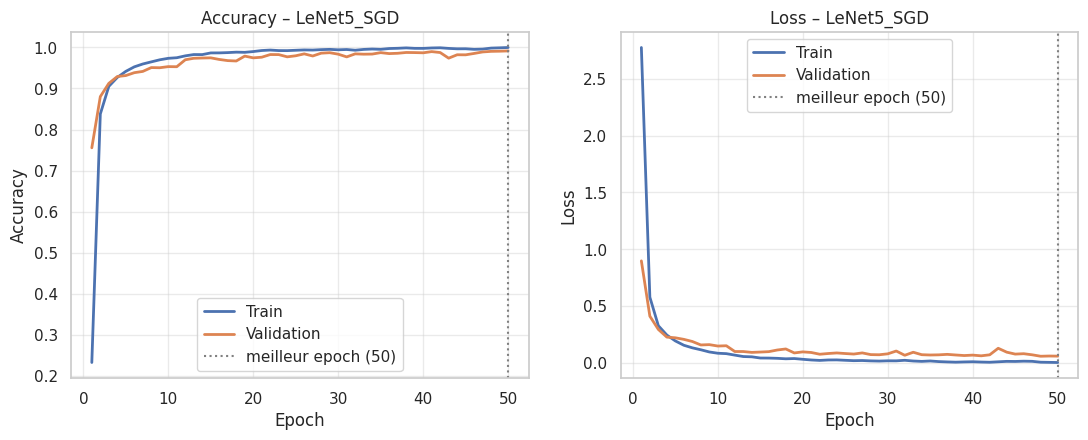

[figure sauvegardée] results/figures/LeNet5_SGD_training_curves.png

--- Résultats LeNet5_SGD (meilleur modèle, epoch 50) ---
Train      : loss=0.0029 | accuracy=0.9995
Validation : loss=0.0586 | accuracy=0.9913
Test       : loss=0.0703 | accuracy=0.9887

Historique – dernières epochs :


,epoch,accuracy,loss,val_accuracy,val_loss
45,46,0.9953,0.0142,0.9852,0.0800
46,47,0.9958,0.0129,0.9889,0.0703
47,48,0.9983,0.0051,0.9903,0.0576
48,49,0.9989,0.0039,0.9907,0.0595
49,50,0.9997,0.0025,0.9913,0.0586



Classification report (test) :


,precision,recall,f1-score,support
ya,1.000,1.000,1.000,234.0
yab,0.979,1.000,0.989,234.0
yach,0.987,0.991,0.989,234.0
yad,0.992,1.000,0.996,234.0
yadd,1.000,1.000,1.000,234.0
yae,1.000,0.987,0.994,234.0
yaf,0.983,0.987,0.985,234.0
yag,0.991,0.991,0.991,234.0
yagh,0.983,0.991,0.987,234.0
yagw,1.000,0.983,0.991,234.0


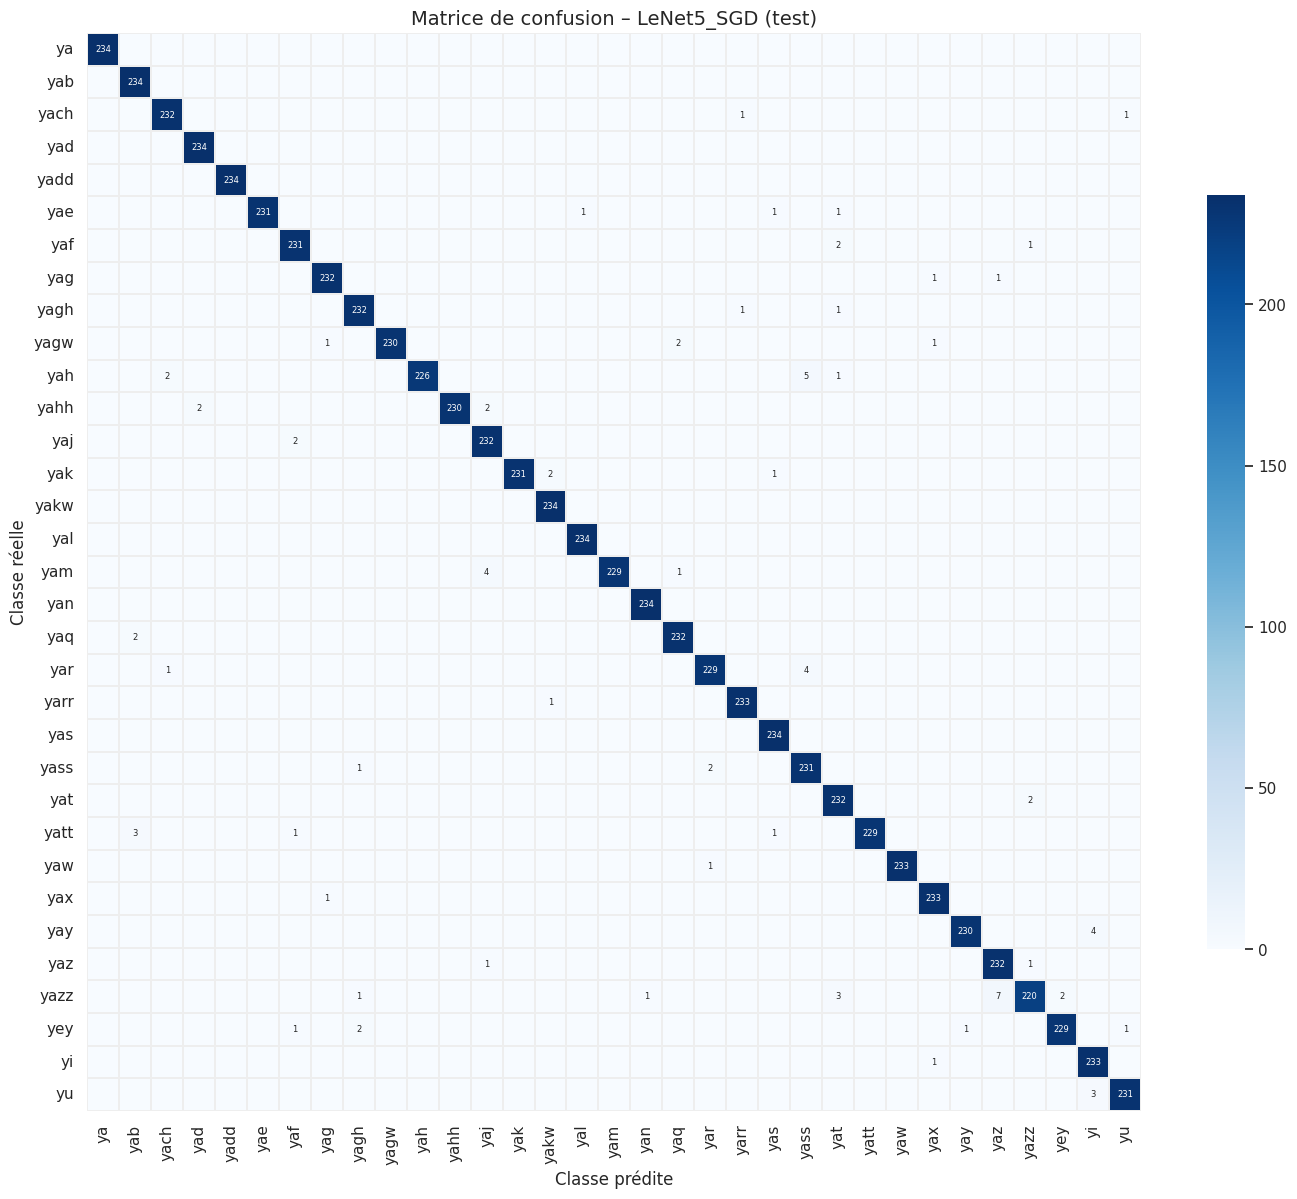

[figure sauvegardée] results/figures/LeNet5_SGD_confusion_matrix.png


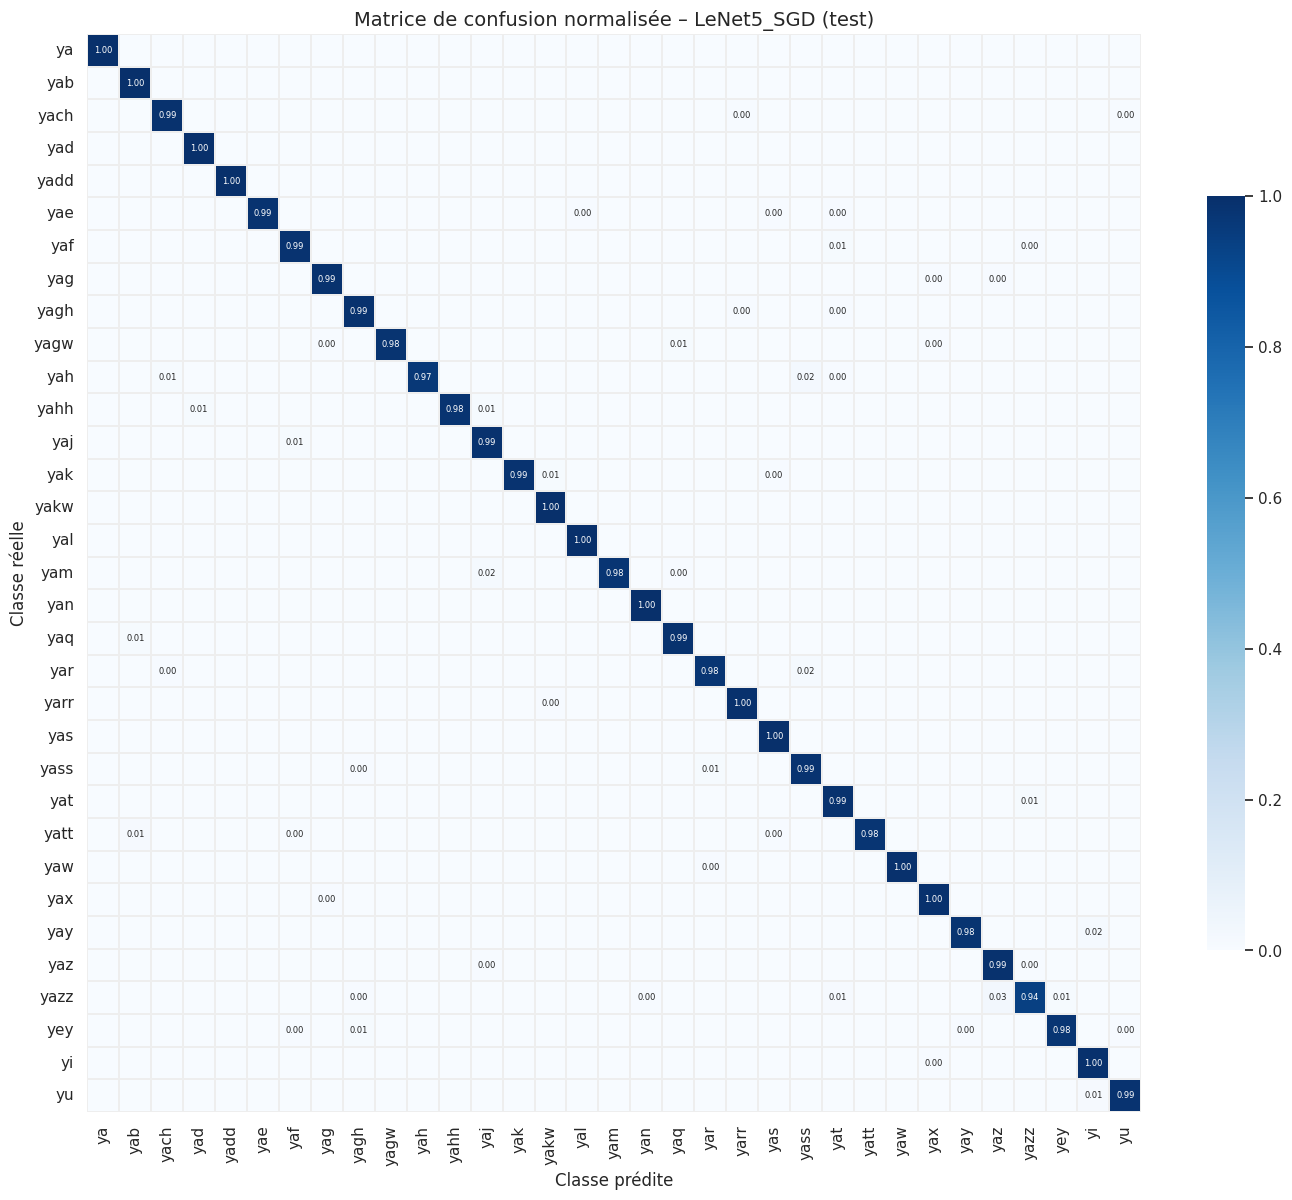

[figure sauvegardée] results/figures/LeNet5_SGD_confusion_matrix_normalized.png


In [39]:
res_sgd = run_experiment("LeNet5_SGD", "sgd", LEARNING_RATE_SGD)

## 12. Expérience 2 – Adam

EXPÉRIENCE : LeNet5_Adam | optimiseur = adam | learning rate = 0.001
Epoch 1/50
564/564 - 21s - 37ms/step - accuracy: 0.5801 - loss: 1.5711 - val_accuracy: 0.8326 - val_loss: 0.6149
Epoch 2/50
564/564 - 21s - 37ms/step - accuracy: 0.8843 - loss: 0.4319 - val_accuracy: 0.8902 - val_loss: 0.3753
Epoch 3/50
564/564 - 40s - 70ms/step - accuracy: 0.9271 - loss: 0.2646 - val_accuracy: 0.9120 - val_loss: 0.2799
Epoch 4/50
564/564 - 21s - 37ms/step - accuracy: 0.9462 - loss: 0.1871 - val_accuracy: 0.9468 - val_loss: 0.1724
Epoch 5/50
564/564 - 19s - 34ms/step - accuracy: 0.9561 - loss: 0.1516 - val_accuracy: 0.9542 - val_loss: 0.1617
Epoch 6/50
564/564 - 23s - 41ms/step - accuracy: 0.9640 - loss: 0.1201 - val_accuracy: 0.9601 - val_loss: 0.1368
Epoch 7/50
564/564 - 41s - 73ms/step - accuracy: 0.9663 - loss: 0.1093 - val_accuracy: 0.9613 - val_loss: 0.1308
Epoch 8/50
564/564 - 20s - 35ms/step - accuracy: 0.9726 - loss: 0.0878 - val_accuracy: 0.9703 - val_loss: 0.1051
Epoch 9/50
564/564 - 20s - 

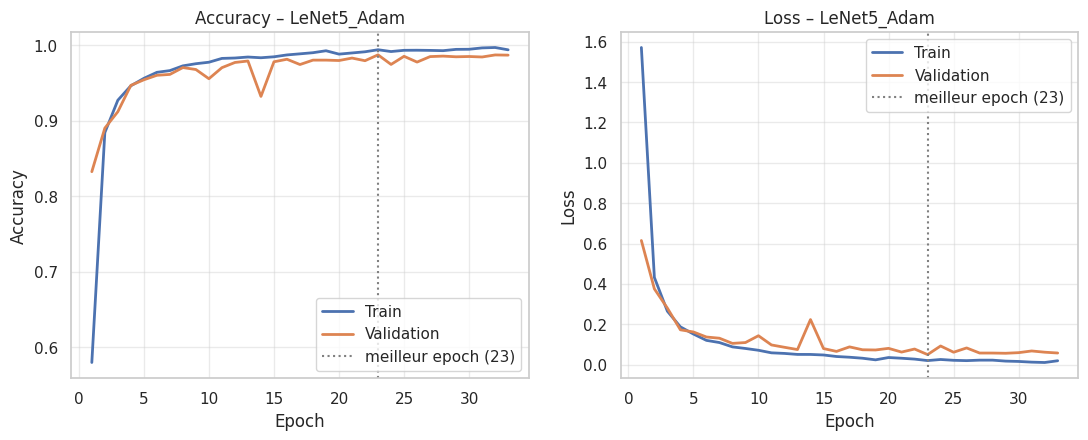

[figure sauvegardée] results/figures/LeNet5_Adam_training_curves.png

--- Résultats LeNet5_Adam (meilleur modèle, epoch 23) ---
Train      : loss=0.0131 | accuracy=0.9960
Validation : loss=0.0497 | accuracy=0.9872
Test       : loss=0.0647 | accuracy=0.9850

Historique – dernières epochs :


,epoch,accuracy,loss,val_accuracy,val_loss
28,29,0.9944,0.0174,0.9846,0.0562
29,30,0.9946,0.0157,0.9850,0.0592
30,31,0.9964,0.0122,0.9843,0.0676
31,32,0.9969,0.0105,0.9871,0.0615
32,33,0.9938,0.0191,0.9868,0.0575



Classification report (test) :


,precision,recall,f1-score,support
ya,0.996,1.000,0.998,234.0
yab,0.979,1.000,0.989,234.0
yach,0.955,1.000,0.977,234.0
yad,0.991,0.991,0.991,234.0
yadd,0.974,0.979,0.977,234.0
yae,0.987,1.000,0.994,234.0
yaf,0.996,0.987,0.991,234.0
yag,0.983,0.996,0.989,234.0
yagh,1.000,0.987,0.994,234.0
yagw,0.991,0.974,0.983,234.0


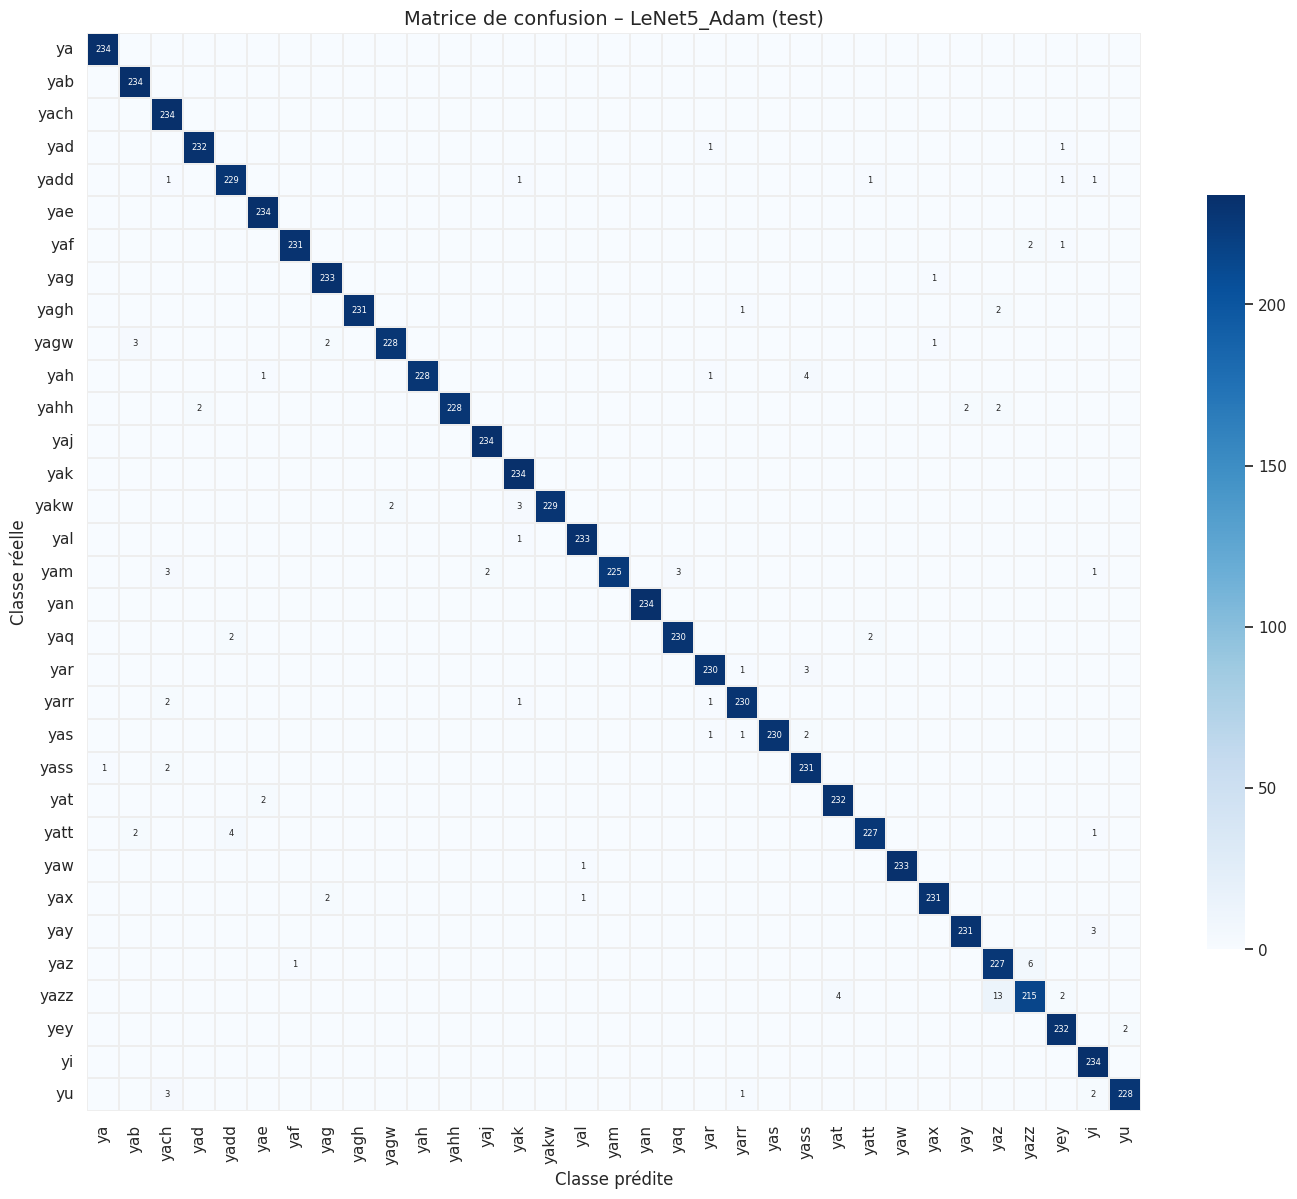

[figure sauvegardée] results/figures/LeNet5_Adam_confusion_matrix.png


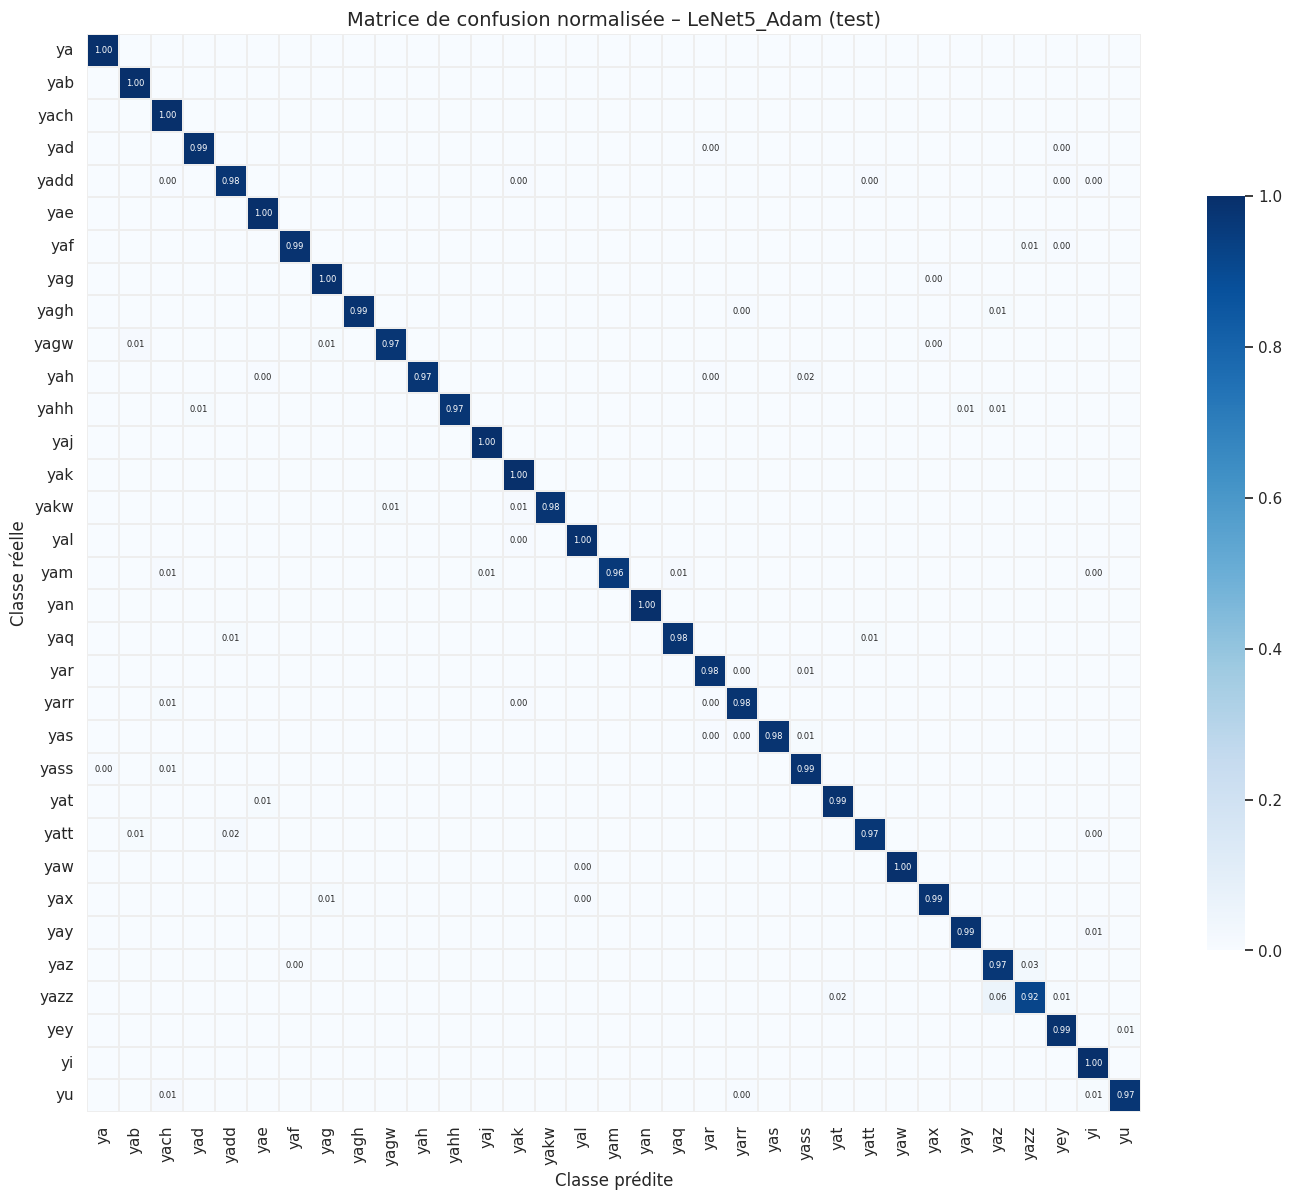

[figure sauvegardée] results/figures/LeNet5_Adam_confusion_matrix_normalized.png


In [40]:
res_adam = run_experiment("LeNet5_Adam", "adam", LEARNING_RATE_ADAM)

## 13. Comparaison SGD / Adam

In [ ]:
def comparison_table(run_names, labels):
    rows = []
    for rn, lab in zip(run_names, labels):
        s = RESULTS[rn]["summary"]
        rows.append({"Optimizer": lab, "Train Accuracy": s["train_accuracy"], "Val Accuracy": s["val_accuracy"],
                     "Test Accuracy": s["test_accuracy"], "Test Loss": s["test_loss"], "Best epoch": s["best_epoch"]})
    return pd.DataFrame(rows)

def to_markdown_table(frame, digits=4):
    header = "| " + " | ".join(frame.columns) + " |"
    sep = "|" + "|".join(["---"] + ["---:"] * (len(frame.columns) - 1)) + "|"
    body = ["| " + " | ".join(f"{v:.{digits}f}" if isinstance(v, float) else str(v) for v in row) + " |"
            for row in frame.itertuples(index=False)]
    return "\n".join([header, sep] + body)

comparison = comparison_table(["LeNet5_SGD", "LeNet5_Adam"], ["SGD", "Adam"])
display(comparison.round(4))
comparison.to_csv(METRICS_DIR / "comparison_sgd_adam.csv", index=False)
(METRICS_DIR / "comparison_sgd_adam.md").write_text(to_markdown_table(comparison))
print(to_markdown_table(comparison))

In [ ]:
# Courbes comparatives SGD vs Adam
h_sgd, h_adam = RESULTS["LeNet5_SGD"]["history"], RESULTS["LeNet5_Adam"]["history"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, label in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(h_sgd["epoch"], h_sgd[metric], "--", color="tab:blue", label="SGD – train")
    ax.plot(h_sgd["epoch"], h_sgd[f"val_{metric}"], "-", color="tab:blue", label="SGD – validation")
    ax.plot(h_adam["epoch"], h_adam[metric], "--", color="tab:orange", label="Adam – train")
    ax.plot(h_adam["epoch"], h_adam[f"val_{metric}"], "-", color="tab:orange", label="Adam – validation")
    ax.set_title(f"{label} : SGD vs Adam"); ax.set_xlabel("Epoch"); ax.set_ylabel(label)
    ax.grid(True, alpha=0.4); ax.legend()
save_fig(fig, "comparison_sgd_adam_train_val.png")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, label in zip(axes, ["val_accuracy", "val_loss"], ["Validation accuracy", "Validation loss"]):
    ax.plot(h_sgd["epoch"], h_sgd[metric], lw=2, label="SGD")
    ax.plot(h_adam["epoch"], h_adam[metric], lw=2, label="Adam")
    ax.set_title(f"{label} : SGD vs Adam"); ax.set_xlabel("Epoch"); ax.set_ylabel(label)
    ax.grid(True, alpha=0.4); ax.legend()
save_fig(fig, "comparison_sgd_adam_validation.png")

# Comparaison des F1-scores par classe (test)
f1 = pd.DataFrame({"SGD": RESULTS["LeNet5_SGD"]["report_df"].iloc[:NUM_CLASSES]["f1-score"].values,
                   "Adam": RESULTS["LeNet5_Adam"]["report_df"].iloc[:NUM_CLASSES]["f1-score"].values}, index=display_names)
fig, ax = plt.subplots(figsize=(14, 4.5))
f1.plot(kind="bar", ax=ax, width=0.8)
ax.set_title("F1-score par classe sur le test set : SGD vs Adam"); ax.set_xlabel("Classe"); ax.set_ylabel("F1-score")
ax.set_ylim(0, 1.05); ax.grid(True, axis="y", alpha=0.4)
save_fig(fig, "comparison_f1_per_class.png")

## 14. Classification reports (précision, rappel, F1, support, moyennes macro / pondérée)

In [42]:
for rn in ["LeNet5_SGD", "LeNet5_Adam"]:
    print(f"\n===== {rn} – test set =====")
    display(RESULTS[rn]["report_df"].round(4))
    rep = RESULTS[rn]["report_df"]
    print("Macro avg    :", rep.loc["macro avg", ["precision", "recall", "f1-score"]].round(4).to_dict())
    print("Weighted avg :", rep.loc["weighted avg", ["precision", "recall", "f1-score"]].round(4).to_dict())


===== LeNet5_SGD – test set =====


,precision,recall,f1-score,support
ya,1.0000,1.0000,1.0000,234.0
yab,0.9791,1.0000,0.9894,234.0
yach,0.9872,0.9915,0.9893,234.0
yad,0.9915,1.0000,0.9957,234.0
yadd,1.0000,1.0000,1.0000,234.0
yae,1.0000,0.9872,0.9935,234.0
yaf,0.9830,0.9872,0.9851,234.0
yag,0.9915,0.9915,0.9915,234.0
yagh,0.9831,0.9915,0.9872,234.0
yagw,1.0000,0.9829,0.9914,234.0


Macro avg    : {'precision': 0.9889, 'recall': 0.9887, 'f1-score': 0.9887}
Weighted avg : {'precision': 0.9889, 'recall': 0.9887, 'f1-score': 0.9887}

===== LeNet5_Adam – test set =====


,precision,recall,f1-score,support
ya,0.9957,1.0000,0.9979,234.0
yab,0.9791,1.0000,0.9894,234.0
yach,0.9551,1.0000,0.9770,234.0
yad,0.9915,0.9915,0.9915,234.0
yadd,0.9745,0.9786,0.9765,234.0
yae,0.9873,1.0000,0.9936,234.0
yaf,0.9957,0.9872,0.9914,234.0
yag,0.9831,0.9957,0.9894,234.0
yagh,1.0000,0.9872,0.9935,234.0
yagw,0.9913,0.9744,0.9828,234.0


Macro avg    : {'precision': 0.9852, 'recall': 0.985, 'f1-score': 0.985}
Weighted avg : {'precision': 0.9852, 'recall': 0.985, 'f1-score': 0.985}


## 15. Visualisation des feature maps
Choisissez l'image du test set avec FM_INDEX (indice dans X_test) ou FM_CLASS_INDEX (première image de cette classe).


########## LeNet5_SGD ##########


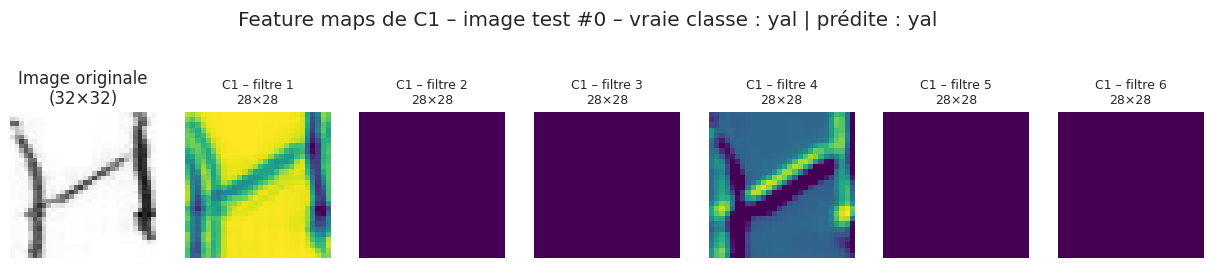

[figure sauvegardée] results/figures/LeNet5_SGD_feature_maps_C1.png


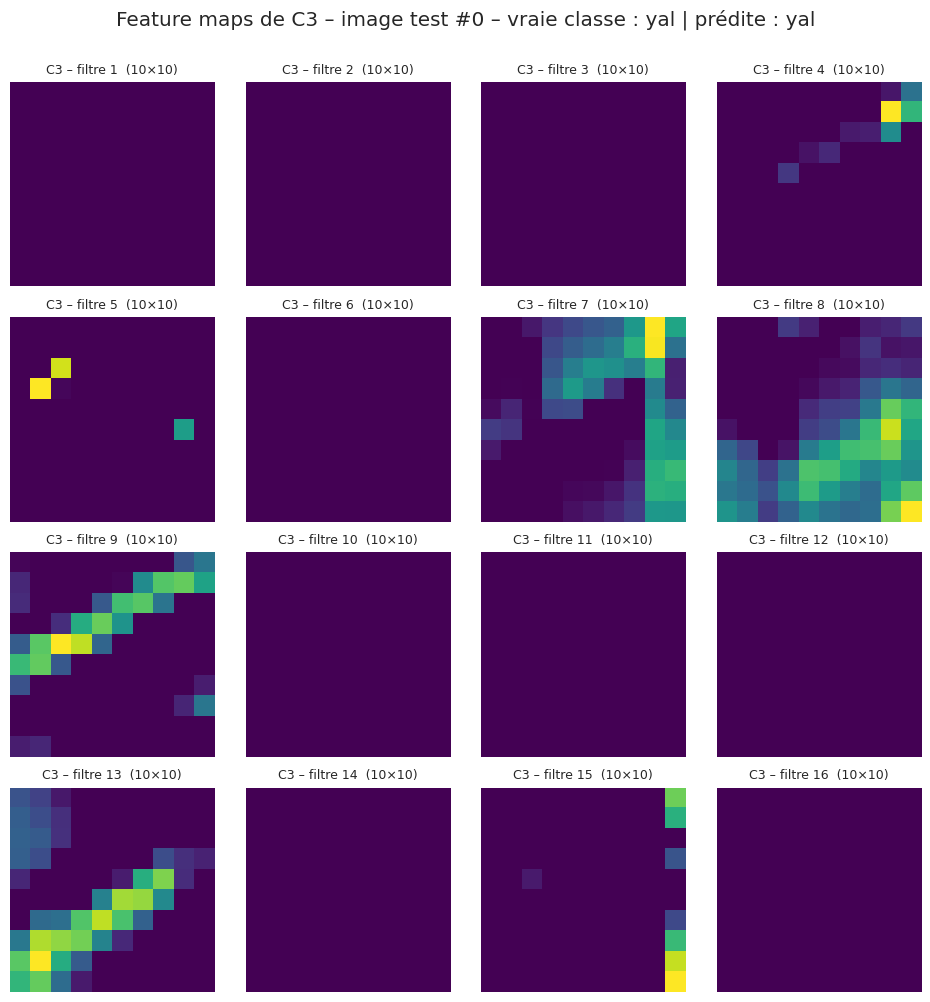

[figure sauvegardée] results/figures/LeNet5_SGD_feature_maps_C3.png

########## LeNet5_Adam ##########


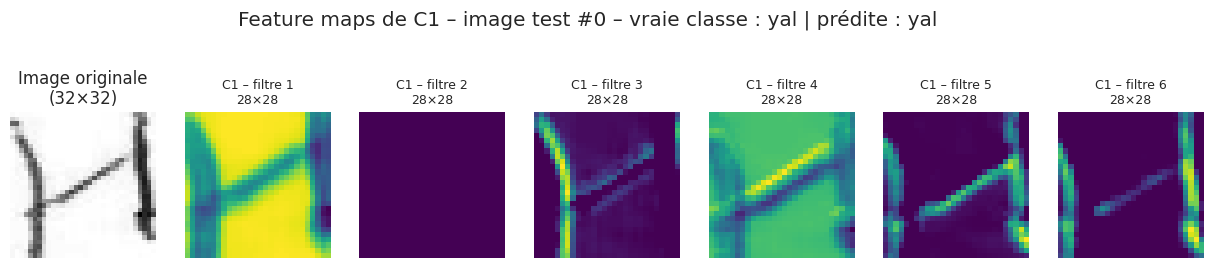

[figure sauvegardée] results/figures/LeNet5_Adam_feature_maps_C1.png


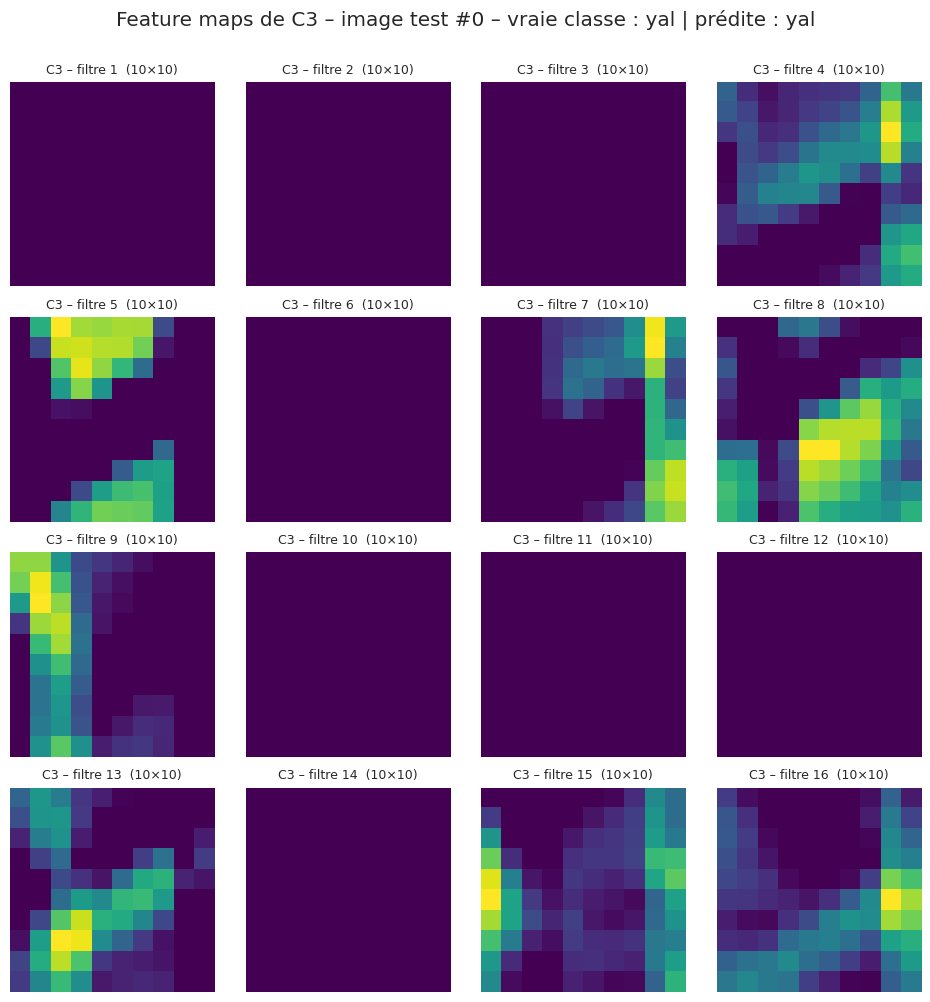

[figure sauvegardée] results/figures/LeNet5_Adam_feature_maps_C3.png


In [43]:
FM_INDEX = 0            # indice dans X_test ; mettre None pour utiliser FM_CLASS_INDEX
FM_CLASS_INDEX = None   # ex. 5 pour la classe d'indice 5

for rn in ["LeNet5_SGD", "LeNet5_Adam"]:
    print(f"\n########## {rn} ##########")
    visualize_feature_maps(RESULTS[rn]["model"], X_test, y_test, display_names,
                           index=FM_INDEX, class_index=FM_CLASS_INDEX, filename_prefix=f"{rn}_feature_maps")

## 16. Analyse automatique des résultats

In [44]:
def analyse_run(run_name, top_k=5):
    res = RESULTS[run_name]
    h, rep, cm, s = res["history"], res["report_df"], res["cm"], res["summary"]
    best_idx = int(h["val_accuracy"].idxmax())
    f1 = rep.iloc[:NUM_CLASSES]["f1-score"]
    support = cm.sum(axis=1)
    errors = support - np.diag(cm)
    err_df = pd.DataFrame({"classe": display_names, "erreurs": errors, "support": support,
                           "taux_erreur": errors / np.maximum(support, 1)})
    err_df = err_df.sort_values(["erreurs", "taux_erreur"], ascending=False).head(top_k).reset_index(drop=True)
    off = cm.copy(); np.fill_diagonal(off, 0)
    order = np.argsort(off.ravel())[::-1][:top_k]
    pairs = [{"vraie": display_names[i], "prédite": display_names[j], "occurrences": int(off[i, j])}
             for i, j in zip(*np.unravel_index(order, off.shape)) if off[i, j] > 0]
    return {"run": run_name,
            "best_val_accuracy": float(h.loc[best_idx, "val_accuracy"]), "best_val_epoch": best_idx + 1,
            "epochs_run": int(len(h)), "test_accuracy": s["test_accuracy"], "test_loss": s["test_loss"],
            "best_f1_class": f1.idxmax(), "best_f1": float(f1.max()),
            "worst_f1_class": f1.idxmin(), "worst_f1": float(f1.min()),
            "n_params": s["params"], "most_errors": err_df, "top_confusions": pairs}

analysis = {rn: analyse_run(rn) for rn in ["LeNet5_SGD", "LeNet5_Adam"]}
for rn, a in analysis.items():
    print(f"\n{'=' * 70}\n{rn}\n{'=' * 70}")
    print(f"Meilleure validation accuracy : {a['best_val_accuracy']:.4f} (epoch {a['best_val_epoch']} / {a['epochs_run']} réalisés)")
    print(f"Test accuracy / loss          : {a['test_accuracy']:.4f} / {a['test_loss']:.4f}")
    print(f"Classe au meilleur F1         : {a['best_f1_class']} (F1 = {a['best_f1']:.4f})")
    print(f"Classe au plus faible F1      : {a['worst_f1_class']} (F1 = {a['worst_f1']:.4f})")
    print(f"Nombre de paramètres          : {a['n_params']:,}")
    print("Classes avec le plus d'erreurs :"); display(a["most_errors"].round(4))
    print("Confusions les plus fréquentes :"); display(pd.DataFrame(a["top_confusions"]))

# Sauvegarde JSON de l'analyse
serializable = {rn: {k: (v.to_dict(orient="records") if isinstance(v, pd.DataFrame) else v) for k, v in a.items()}
                for rn, a in analysis.items()}
(METRICS_DIR / "automatic_analysis.json").write_text(json.dumps(serializable, indent=2, ensure_ascii=False))


LeNet5_SGD
Meilleure validation accuracy : 0.9913 (epoch 50 / 50 réalisés)
Test accuracy / loss          : 0.9887 / 0.0703
Classe au meilleur F1         : ya (F1 = 1.0000)
Classe au plus faible F1      : yazz (F1 = 0.9607)
Nombre de paramètres          : 63,661
Classes avec le plus d'erreurs :


,classe,erreurs,support,taux_erreur
0,yazz,14,234,0.0598
1,yah,8,234,0.0342
2,yam,5,234,0.0214
3,yar,5,234,0.0214
4,yatt,5,234,0.0214


Confusions les plus fréquentes :


,vraie,prédite,occurrences
0,yazz,yaz,7
1,yah,yass,5
2,yar,yass,4
3,yay,yi,4
4,yam,yaj,4



LeNet5_Adam
Meilleure validation accuracy : 0.9872 (epoch 23 / 33 réalisés)
Test accuracy / loss          : 0.9850 / 0.0647
Classe au meilleur F1         : yan (F1 = 1.0000)
Classe au plus faible F1      : yazz (F1 = 0.9409)
Nombre de paramètres          : 63,661
Classes avec le plus d'erreurs :


,classe,erreurs,support,taux_erreur
0,yazz,19,234,0.0812
1,yam,9,234,0.0385
2,yatt,7,234,0.0299
3,yaz,7,234,0.0299
4,yagw,6,234,0.0256


Confusions les plus fréquentes :


,vraie,prédite,occurrences
0,yazz,yaz,13
1,yaz,yazz,6
2,yazz,yat,4
3,yatt,yadd,4
4,yah,yass,4


3078

In [45]:
# Bloc de synthèse à copier-coller pour la rédaction de l'article
lines = ["=== SYNTHÈSE À ENVOYER ===",
         f"Dataset : {len(df_valid)} images, {NUM_CLASSES} classes | Train/Val/Test = {len(y_train)}/{len(y_val)}/{len(y_test)}",
         f"Config : batch={BATCH_SIZE}, epochs max={EPOCHS}, early stopping patience={EARLY_STOPPING_PATIENCE}, activation={ACTIVATION}, "
         f"SGD lr={LEARNING_RATE_SGD} (momentum={SGD_MOMENTUM}), Adam lr={LEARNING_RATE_ADAM}, seed={SEED}",
         f"Paramètres du modèle : {model_ref.count_params():,}", "", to_markdown_table(comparison), ""]
for rn, a in analysis.items():
    lines.append(f"{rn}: best val acc={a['best_val_accuracy']:.4f} (epoch {a['best_val_epoch']}), test acc={a['test_accuracy']:.4f}, "
                 f"meilleur F1={a['best_f1_class']} ({a['best_f1']:.4f}), plus faible F1={a['worst_f1_class']} ({a['worst_f1']:.4f})")
    lines.append(f"   confusions principales : {a['top_confusions']}")
print("\n".join(lines))
(METRICS_DIR / "synthese.txt").write_text("\n".join(lines))

=== SYNTHÈSE À ENVOYER ===
Dataset : 51480 images, 33 classes | Train/Val/Test = 36035/7723/7722
Config : batch=64, epochs max=50, early stopping patience=10, activation=relu, SGD lr=0.01 (momentum=0.9), Adam lr=0.001, seed=42
Paramètres du modèle : 63,661

| Optimizer | Train Accuracy | Val Accuracy | Test Accuracy | Test Loss | Best epoch |
|---|---:|---:|---:|---:|---:|
| SGD | 0.9995 | 0.9913 | 0.9887 | 0.0703 | 50 |
| Adam | 0.9960 | 0.9872 | 0.9850 | 0.0647 | 23 |

LeNet5_SGD: best val acc=0.9913 (epoch 50), test acc=0.9887, meilleur F1=ya (1.0000), plus faible F1=yazz (0.9607)
   confusions principales : [{'vraie': 'yazz', 'prédite': 'yaz', 'occurrences': 7}, {'vraie': 'yah', 'prédite': 'yass', 'occurrences': 5}, {'vraie': 'yar', 'prédite': 'yass', 'occurrences': 4}, {'vraie': 'yay', 'prédite': 'yi', 'occurrences': 4}, {'vraie': 'yam', 'prédite': 'yaj', 'occurrences': 4}]
LeNet5_Adam: best val acc=0.9872 (epoch 23), test acc=0.9850, meilleur F1=yan (1.0000), plus faible F1=yazz 

1314


 Section **séparée** du modèle de référence, qui n'est pas modifié.
 Améliorations testées : data augmentation légère (rotation, translation, zoom), Batch Normalization, Dropout, réduction du learning rate sur plateau (Adam).
 Mettre RUN_BONUS = False pour la sauter.

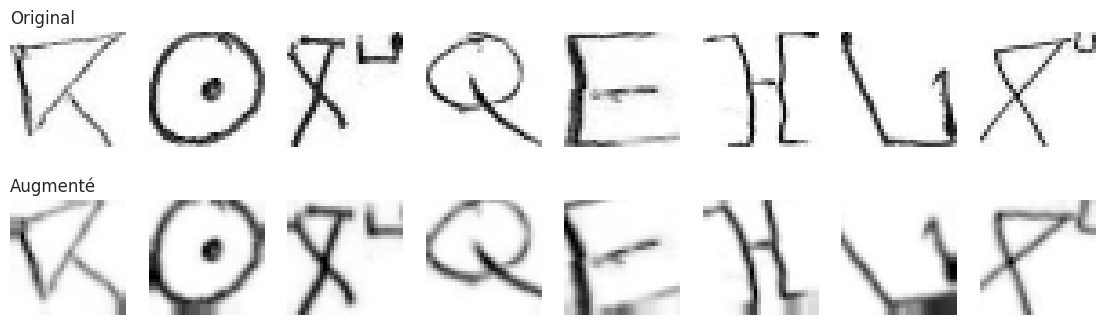

[figure sauvegardée] results/figures/bonus_augmentation_preview.png
EXPÉRIENCE : LeNet5_Bonus_Adam | optimiseur = adam | learning rate = 0.001
Epoch 1/50
564/564 - 34s - 61ms/step - accuracy: 0.6041 - loss: 1.3645 - val_accuracy: 0.3954 - val_loss: 3.3076 - learning_rate: 0.0010
Epoch 2/50
564/564 - 30s - 53ms/step - accuracy: 0.8507 - loss: 0.4828 - val_accuracy: 0.5996 - val_loss: 2.0170 - learning_rate: 0.0010
Epoch 3/50
564/564 - 31s - 55ms/step - accuracy: 0.8954 - loss: 0.3465 - val_accuracy: 0.2407 - val_loss: 7.2690 - learning_rate: 0.0010
Epoch 4/50
564/564 - 42s - 74ms/step - accuracy: 0.9093 - loss: 0.2988 - val_accuracy: 0.3276 - val_loss: 7.9283 - learning_rate: 0.0010
Epoch 5/50
564/564 - 30s - 54ms/step - accuracy: 0.9152 - loss: 0.2759 - val_accuracy: 0.6065 - val_loss: 2.0091 - learning_rate: 0.0010
Epoch 6/50
564/564 - 30s - 53ms/step - accuracy: 0.9272 - loss: 0.2372 - val_accuracy: 0.3069 - val_loss: 6.9163 - learning_rate: 0.0010
Epoch 7/50
564/564 - 31s - 54ms/ste

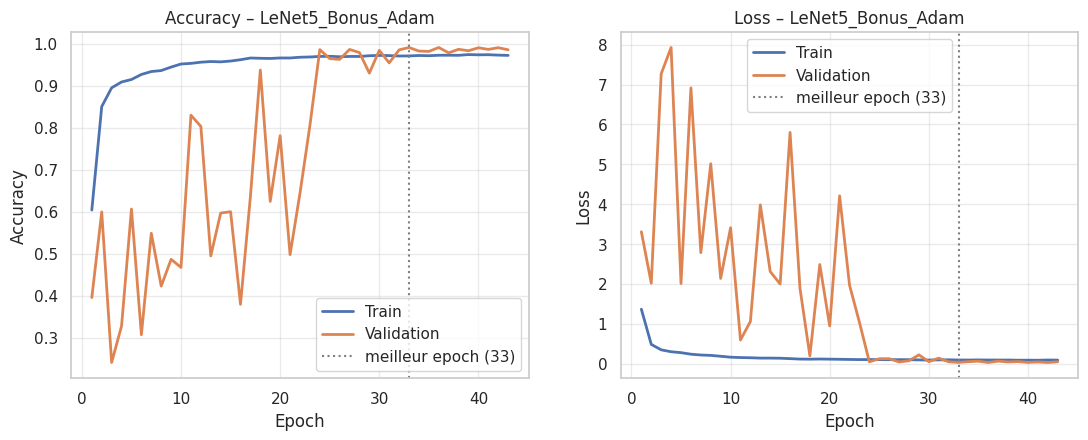

[figure sauvegardée] results/figures/LeNet5_Bonus_Adam_training_curves.png

--- Résultats LeNet5_Bonus_Adam (meilleur modèle, epoch 33) ---
Train      : loss=0.0205 | accuracy=0.9944
Validation : loss=0.0316 | accuracy=0.9915
Test       : loss=0.0274 | accuracy=0.9921

Historique – dernières epochs :


,epoch,accuracy,loss,val_accuracy,val_loss,learning_rate
38,39,0.9746,0.0859,0.9837,0.0518,0.0001
39,40,0.9740,0.0873,0.9908,0.0315,0.0001
40,41,0.9742,0.0854,0.9869,0.0427,0.0000
41,42,0.9733,0.0913,0.9909,0.0292,0.0000
42,43,0.9726,0.0893,0.9860,0.0469,0.0000



Classification report (test) :


,precision,recall,f1-score,support
ya,1.000,1.000,1.000,234.0
yab,1.000,1.000,1.000,234.0
yach,1.000,0.991,0.996,234.0
yad,0.996,1.000,0.998,234.0
yadd,0.979,0.996,0.987,234.0
yae,0.987,1.000,0.994,234.0
yaf,0.971,1.000,0.985,234.0
yag,0.992,1.000,0.996,234.0
yagh,0.991,0.996,0.994,234.0
yagw,1.000,0.991,0.996,234.0


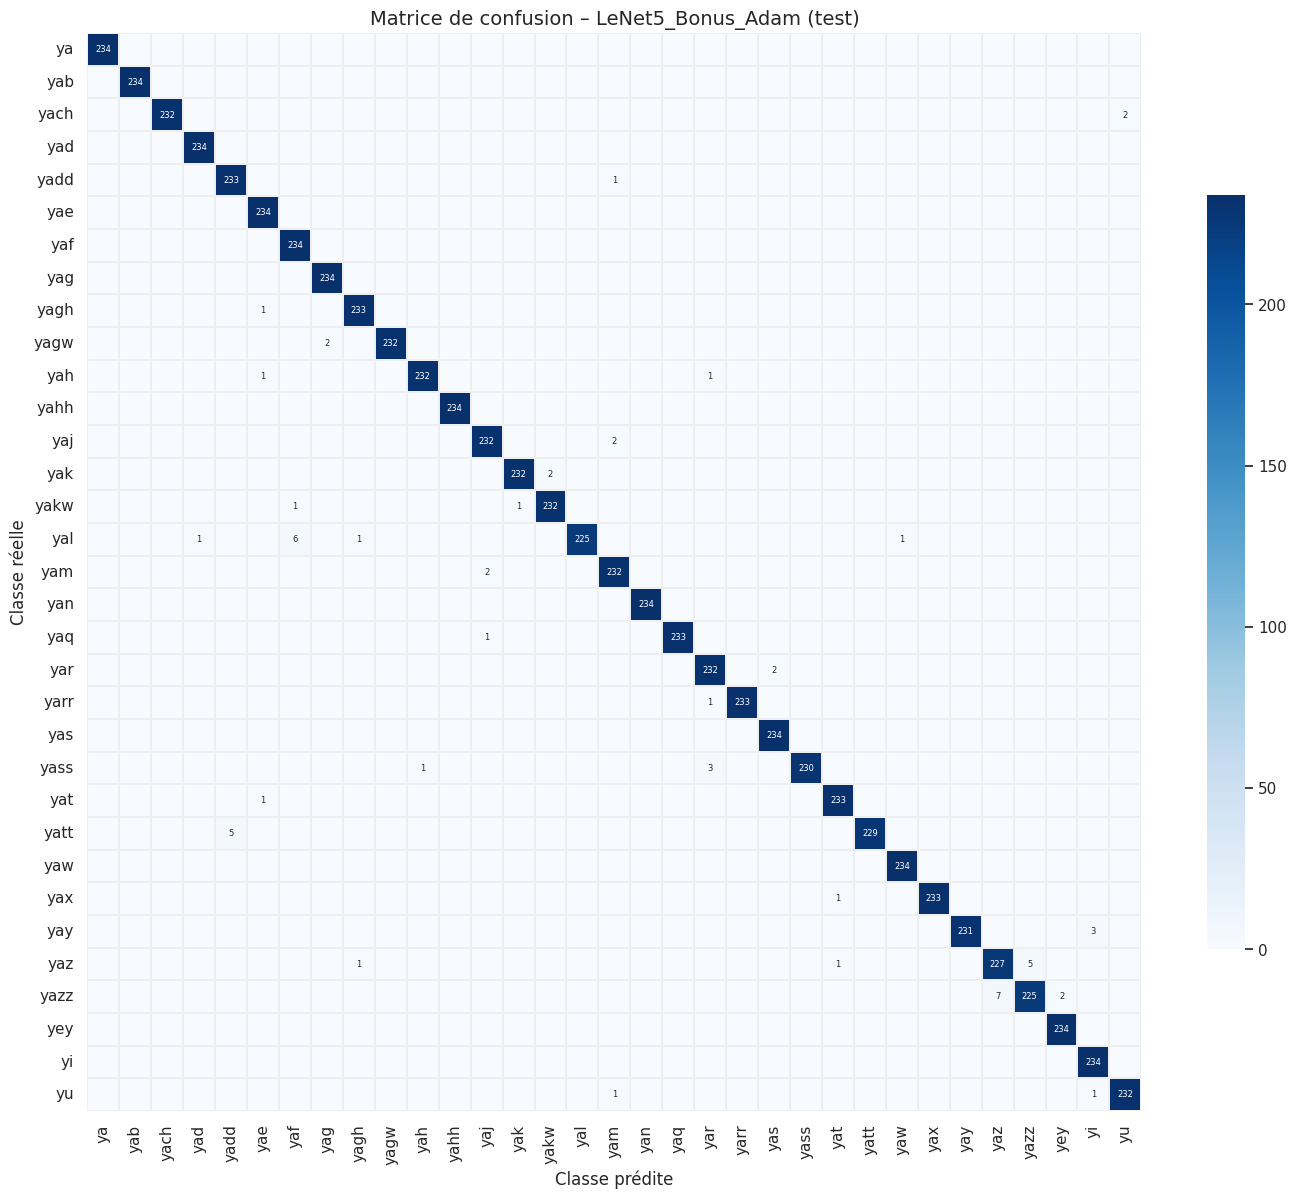

[figure sauvegardée] results/figures/LeNet5_Bonus_Adam_confusion_matrix.png


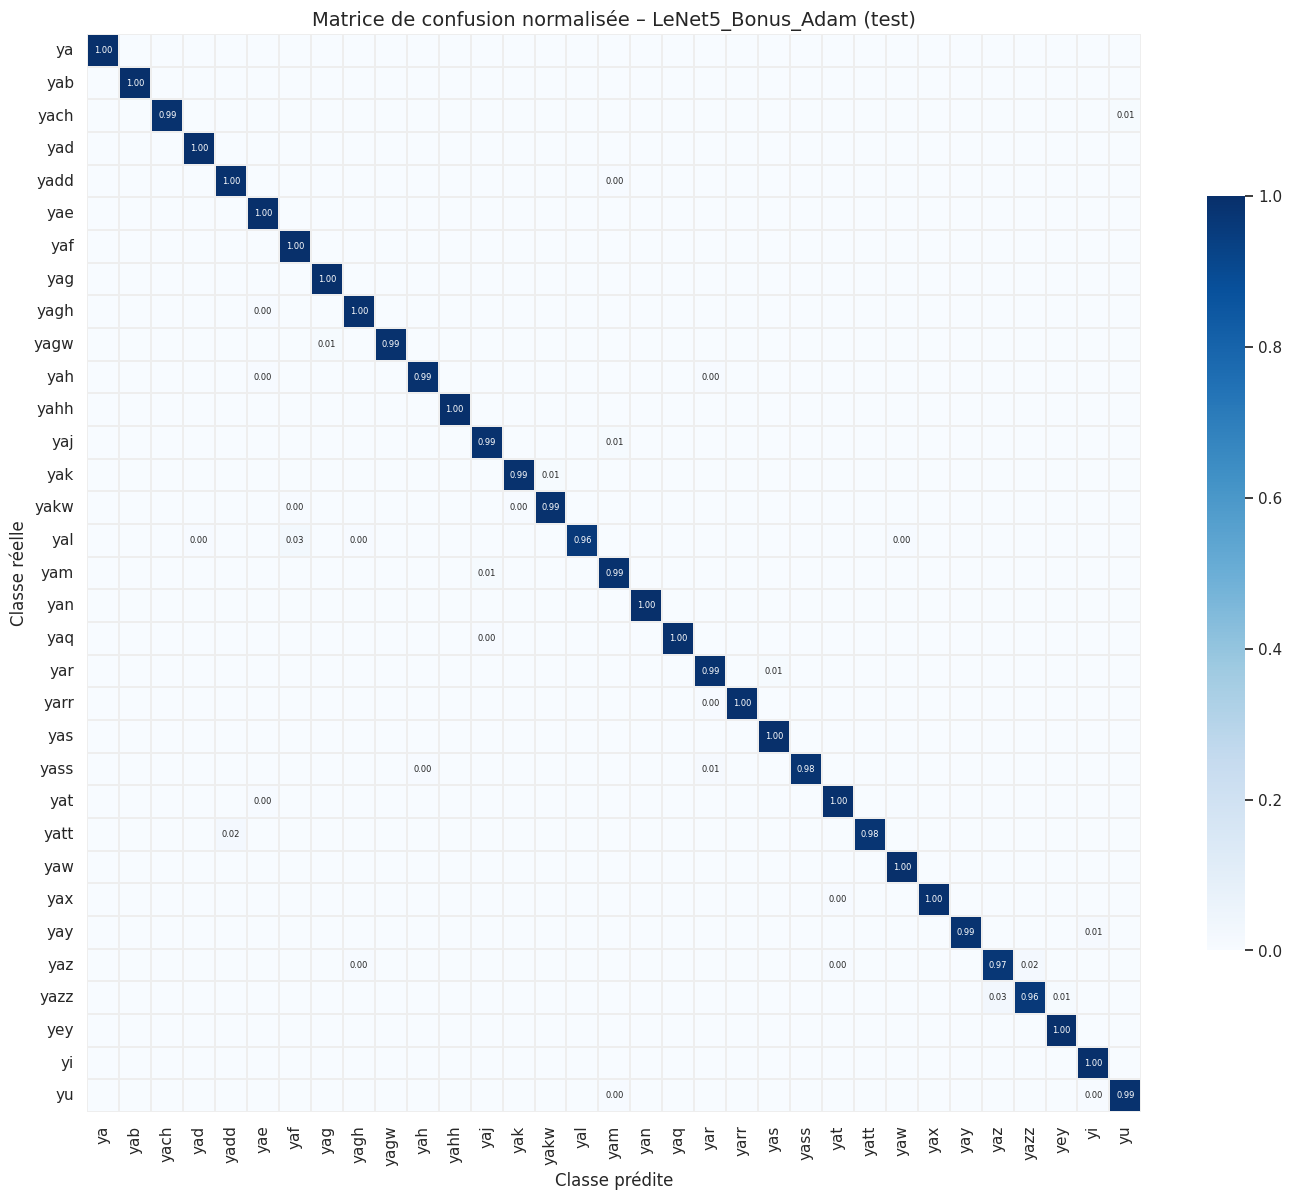

[figure sauvegardée] results/figures/LeNet5_Bonus_Adam_confusion_matrix_normalized.png


,Optimizer,Train Accuracy,Val Accuracy,Test Accuracy,Test Loss,Best epoch
0,SGD (référence),0.9995,0.9913,0.9887,0.0703,50
1,Adam (référence),0.9960,0.9872,0.9850,0.0647,23
2,Adam + aug + BN + Dropout (bonus),0.9944,0.9915,0.9921,0.0274,33


In [23]:
RUN_BONUS = True
BONUS_DROPOUT = 0.3

def build_lenet5_bonus(dropout=BONUS_DROPOUT, activation=ACTIVATION, name="LeNet5_Bonus"):
    """Variante améliorée (hors sujet) : mêmes dimensions que LeNet-5, avec BatchNorm + Dropout."""
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, NUM_CHANNELS), name="Input")
    x = layers.Conv2D(CONV1_FILTERS, CONV1_KERNEL, padding="valid", name="C1")(inputs)
    x = layers.BatchNormalization(name="BN1")(x); x = layers.Activation(activation)(x)
    x = layers.AveragePooling2D(POOL_SIZE, POOL_STRIDE, name="S2")(x)
    x = layers.Conv2D(CONV2_FILTERS, CONV2_KERNEL, padding="valid", name="C3")(x)
    x = layers.BatchNormalization(name="BN2")(x); x = layers.Activation(activation)(x)
    x = layers.AveragePooling2D(POOL_SIZE, POOL_STRIDE, name="S4")(x)
    x = layers.Flatten(name="Flatten")(x)
    x = layers.Dense(FC1_UNITS, activation=activation, name="C5")(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(FC2_UNITS, activation=activation, name="F6")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="Output")(x)
    return keras.Model(inputs, outputs, name=name)

if RUN_BONUS:
    augmenter = keras.Sequential([
        layers.RandomRotation(0.05, fill_mode="nearest"),
        layers.RandomTranslation(0.08, 0.08, fill_mode="nearest"),
        layers.RandomZoom(0.1, fill_mode="nearest"),
    ], name="augmentation")

    train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
                .shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE)
                .map(lambda xb, yb: (augmenter(xb, training=True), yb), num_parallel_calls=tf.data.AUTOTUNE)
                .prefetch(tf.data.AUTOTUNE))

    # Aperçu de l'augmentation
    sample = X_train[:8]
    aug = augmenter(sample, training=True).numpy()
    fig, axes = plt.subplots(2, 8, figsize=(14, 4))
    for i in range(8):
        axes[0, i].imshow(sample[i, ..., 0], cmap="gray"); axes[0, i].axis("off")
        axes[1, i].imshow(aug[i, ..., 0], cmap="gray"); axes[1, i].axis("off")
    axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("Augmenté", loc="left")
    save_fig(fig, "bonus_augmentation_preview.png")

    res_bonus = run_experiment("LeNet5_Bonus_Adam", "adam", LEARNING_RATE_ADAM, builder=build_lenet5_bonus,
                               train_dataset=train_ds,
                               extra_callbacks=[keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                                                                 patience=4, min_lr=1e-5, verbose=1)])

    full = comparison_table(["LeNet5_SGD", "LeNet5_Adam", "LeNet5_Bonus_Adam"],
                            ["SGD (référence)", "Adam (référence)", "Adam + aug + BN + Dropout (bonus)"])
    display(full.round(4))
    full.to_csv(METRICS_DIR / "comparison_with_bonus.csv", index=False)
    (METRICS_DIR / "comparison_with_bonus.md").write_text(to_markdown_table(full))
else:
    print("Expérience bonus désactivée.")

## 17. Export des résultats

In [46]:
print("Contenu de results/ :")
for sub in (FIG_DIR, MODEL_DIR, METRICS_DIR):
    print(f"\n{sub}/")
    for f in sorted(sub.glob("*")):
        print(f"   {f.name}")

archive = shutil.make_archive("results_lenet5_tifinagh", "zip", RESULTS_DIR)
print("\nArchive créée :", archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

Contenu de results/ :

results/figures/
   LeNet5_Adam_confusion_matrix.png
   LeNet5_Adam_confusion_matrix_normalized.png
   LeNet5_Adam_feature_maps_C1.png
   LeNet5_Adam_feature_maps_C3.png
   LeNet5_Adam_training_curves.png
   LeNet5_Bonus_Adam_confusion_matrix.png
   LeNet5_Bonus_Adam_confusion_matrix_normalized.png
   LeNet5_Bonus_Adam_training_curves.png
   LeNet5_SGD_confusion_matrix.png
   LeNet5_SGD_confusion_matrix_normalized.png
   LeNet5_SGD_feature_maps_C1.png
   LeNet5_SGD_feature_maps_C3.png
   LeNet5_SGD_training_curves.png
   bonus_augmentation_preview.png
   class_distribution_full.png
   class_distribution_splits.png
   comparison_f1_per_class.png
   comparison_sgd_adam_train_val.png
   comparison_sgd_adam_validation.png
   examples_one_per_class.png

results/models/
   LeNet5_Adam_best.keras
   LeNet5_Bonus_Adam_best.keras
   LeNet5_SGD_best.keras

results/metrics/
   LeNet5_Adam_classification_report.csv
   LeNet5_Adam_confusion_matrix.csv
   LeNet5_Adam_history.c

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>